# 🎓 Tugas Terstruktur dan Milestone UAS Pertemuan 11
## Evaluasi Klasifikasi, Pemilihan Threshold Berbasis Biaya, Kalibrasi Probabilitas, dan Proposal Artikel Individual (Target SINTA 4)

**Keterkaitan:** Modul 11 — Evaluasi Klasifikasi dan Ambang Keputusan  
**Moda:** Individual dan asinkron melalui Google Classroom  
**Dosen Pengampu:** Bapak Ahmad Tabrani  
**Mahasiswa:** Fadli Hifziansyah (NIM: `241730042` | Kelas: `5 INF B`)  
**Tenggat:** Mengikuti jadwal pada Google Classroom (27 November 2026 pukul 23.59 WIB)

Notebook ini adalah **tugas terstruktur sekaligus Milestone Proyek UAS Individual**, bukan latihan terbimbing. Seluruh jawaban, kode, perhitungan metrik, diagram visualisasi, analisis kesalahan, hingga proposal artikel ilmiah target jurnal **SINTA 4** di dalam berkas ini disusun secara mandiri menggunakan bahasa mahasiswa yang lugas dan dapat dipertanggungjawabkan.

## 🗺️ 0. Panduan Alur Kerja (Flow Text) & Navigasi Notebook — Pertemuan 11

> 💡 **Tujuan Bagian Ini:**  
> Bagian ini saya tambahkan sebagai panduan ringkas agar alur pengerjaan (*workflow*), hubungan antar-sel, dan hasil utama pada **Pertemuan 11: Evaluasi Klasifikasi, Threshold, Kalibrasi Probabilitas, dan Proposal Artikel UAS** dapat dibaca dengan nyaman oleh siapa saja, termasuk pembaca awam.

### A. Ringkasan Singkat Praktikum Pertemuan 11
Pada Pertemuan 11 ini, saya melanjutkan model klasifikasi utama dari **Proyek UAS Sistem Peringatan Dini Risiko Putus Studi (*Dropout*) Mahasiswa Tingkat Pertama Program Studi Informatika** ($N = 800$ mahasiswa unik, mengacu pada skema [UCI Machine Learning Repository #697](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success); [Realinho et al., 2022](https://www.mdpi.com/2306-5729/7/11/146), dengan proporsi kelas positif *dropout* sebesar **28,75%**). Fokus utama kita bukan lagi sekadar melatih model, melainkan menjawab pertanyaan praktis: **"Jika model mengeluarkan angka peluang risiko antara `0,00` sampai `1,00`, pada batas angka (*threshold*) berapa seorang mahasiswa harus dipanggil konseling oleh Dosen Pembimbing Akademik (DPA)?"**

Seluruh pemilihan *threshold* dilakukan murni menggunakan **probabilitas pada partisi Validasi ($n = 160$, terdiri dari 114 mahasiswa bertahan dan 46 mahasiswa *dropout*)**, sedangkan **partisi Test ($n = 160$)** dikunci rapat dan hanya dibuka satu kali di tahap akhir. Dari hasil eksperimen diperoleh lima temuan utama:
1. **Perbandingan Tiga Confusion Matrix (`0,30`, `0,50`, dan `0,70`) di Partisi Validasi:** Memakai batas bawaan `0,50` ternyata membuat **16 dari 46 mahasiswa *dropout* terlewat (`FN = 16`, Recall hanya `65,22%`)**, dan menaikkan batas ke `0,70` membuat **31 mahasiswa *dropout* terlewat (`FN = 31`, Recall anjlok ke `32,61%`)**. Sebaliknya, menurunkan batas ke **`0,30`** berhasil menangkap **42 dari 46 mahasiswa *dropout* (`Recall = 91,30%`, `FN` tinggal 4 orang)** dengan `Specificity = 85,09%` dan `F1-Score = 0,8000`.
2. **Evaluasi Kurva ROC-AUC dan PR-AUC:** Model *Logistic Regression Terkalibrasi* meraih **ROC-AUC Validasi = `0,9355`** (vs. baseline acak `0,5000`) dan **PR-AUC Validasi = `0,9016`** (lebih dari 3 kali lipat di atas baseline prevalensi kelas positif **`0,2875`**).
3. **Pemeriksaan Kalibrasi Probabilitas:** Model `LogisticRegression` dengan probabilitas alami (*Platt/Sigmoid calibrated*) memiliki kualitas kalibrasi jauh lebih jujur (**Brier Score Validasi = `0,0930`**, dan di partisi Test mencapai **Brier Score = `0,1126` dengan *Expected Calibration Error* / ECE hanya `0,0298` [2,98%]**) dibandingkan model `class_weight='balanced'` tanpa kalibrasi yang cenderung membesarkan angka peluang di rentang menengah (`Brier Score Val = 0,1123`, `ECE Val = 0,1365`) maupun *Decision Tree* (`Brier Score Val = 0,1707`).
4. **Keputusan Berbasis Matriks Biaya ($C_{\text{FP}} = 1$ vs. $C_{\text{FN}} = 4$) & Kapasitas Kuota DPA:** Dengan biaya 1 kasus *dropout* yang terlewat ($C_{\text{FN}} = 4$ unit / Rp600.000) empat kali lebih mahal daripada 1 panggilan konseling salah sasaran ($C_{\text{FP}} = 1$ unit / Rp150.000), **Total Biaya Kesalahan di Validasi mencapai titik paling minimum pada `threshold = 0,30` yaitu `33 unit` (Rp4,95 juta, memanggil 59 mahasiswa)**—menghemat **50% biaya** dibandingkan `threshold = 0,50` (`66 unit` / Rp9,90 juta) dan `threshold = 0,70` (`124 unit` / Rp18,60 juta). Bila kuota tatap muka DPA dibatasi ketat maksimal 55 kursi, maka **`threshold = 0,35`** memanggil **53 mahasiswa** dengan **Total Biaya = `42 unit` (Rp6,30 juta, Recall `84,78%`)**. Saat diuji satu kali pada **partisi Test Final ($n=160$)**, *threshold* operasional ini terbukti konsisten menghasilkan biaya terendah (**`66 unit`** pada $t=0{,}35$ dan **`69 unit`** pada $t=0{,}30$, mengalahkan $t=0{,}50$ sebesar `74 unit` dan $t=0{,}70$ sebesar `106 unit`).
5. **Proposal Artikel UAS & Verifikasi Jurnal SINTA 4:** Disusun proposal artikel ilmiah lengkap beserta bukti verifikasi awal pada jurnal terakreditasi **SINTA 4**, yaitu **JIKO (Jurnal Informatika dan Komputer — UTDI, ID SINTA 103)** sebagai target utama, serta **KOMPUTA (UNIKOM, ID SINTA 8075)** dan **Infotek (Universitas Hamzanwadi, SK 225/E/KPT/2022)** sebagai target cadangan.

### B. Alur Kerja (*Step-by-Step Flow*)
```text
[MULAI] -> [1. Siapkan Data Proyek UAS (N=800 Unik: Train=480, Val=160, Test=160, Positif=28,75%)] -> [[2. Latih Pipeline Anti-Leakage & Ambil Probabilitas di Partisi Validasi]] -> [3. Hitung 3 Confusion Matrix (t=0,30; 0,50; 0,70) & Tabel Trade-Off 8 Threshold] -> [4. Hitung & Plot Kurva ROC (AUC=0,9355), PR Curve (AUC=0,9016 vs Baseline 0,2875), & Kurva Kalibrasi (Brier=0,0930)] -> [5. Susun Matriks Biaya (C_FP=1, C_FN=4) & Pilih Threshold Operasional (t*=0,30 / 0,35)] -> <6. Kunci Threshold & Uji 1x di Data Test Final (n=160)?> --(YA)--> [7. Analisis 3 Segmen Kesalahan + Susun Proposal Artikel UAS & Bukti Jurnal SINTA 4] -> [SELESAI]
```

### C. Daftar Navigasi Urutan Sel (Cell 00 s.d. Cell 34)
| Indeks Sel | Jenis Sel | Bagian / Topik | Penjelasan Singkat |
| :--- | :--- | :--- | :--- |
| **Cell 00** | Markdown | Judul Utama & Konteks Tugas | Judul Pertemuan 11, identitas tugas, dan keterkaitan Modul 11. |
| **Cell 01** | Markdown | Bagian 0 — Panduan Alur Kerja | Ringkasan hasil utama, alur kerja teks, dan tabel daftar isi sel. |
| **Cell 02** | Code | Flowchart Alur Pengerjaan | Menggambar diagram alir (*flowchart*) monokrom standar ISO 5807 untuk Pertemuan 11. |
| **Cell 03–08** | Markdown | Bagian 1 s.d. Bagian 6 | Tujuan produk akhir, skenario tugas, langkah wajib, bukti wajib, rubrik penilaian, dan pengantar identitas. |
| **Cell 09** | Code | Identitas Mahasiswa (Bagian 6) | Kamus biodata Fadli Hifziansyah (NIM `241730042`, Kelas `5 INF B`), judul tugas, dan sumber dataset. |
| **Cell 10–11** | Markdown & Code | Bagian 7 — Persiapan Lingkungan | Mengimpor pustaka standar Python (`numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`) dan `SEED = 42`. |
| **Cell 12** | Markdown | **Bagian Khusus — Kajian Teori (6 Komponen)** | Penjelasan 10 konsep utama Pertemuan 11 dengan 6 komponen lengkap menggunakan bahasa yang mudah dipahami. |
| **Cell 13–14** | Markdown | Bagian 8 — Rumusan Analisis & 5 Latihan Analitis | Jawaban lengkap 5 pertanyaan perumusan masalah sekaligus pembahasan **5 Latihan Analitis** dari dosen. |
| **Cell 15–17** | Markdown & Code | Bagian 9 — Implementasi Threshold, AUC, & Kalibrasi | Kode pembuatan probabilitas Validasi, cetak 3 Confusion Matrix (`0,30; 0,50; 0,70`), tabel 8 threshold, ROC-AUC, PR-AUC, dan tabel kalibrasi 5 bin. |
| **Cell 18–19** | Markdown | Bagian 10 — Audit Data, Validasi, & Kalibrasi | Dokumentasi audit pencegahan *threshold leakage*, analisis kalibrasi probabilitas, dan alasan pemilihan threshold. |
| **Cell 20–22** | Markdown & Code | Bagian 11 — Matriks Biaya, Evaluasi Test, & Proposal UAS | Tabel matriks biaya FP/FN, verifikasi satu kali di partisi Test ($n=160$), kamus `proposal_uas`, rencana waktu, dan tabel bukti verifikasi 3 Jurnal SINTA 4. |
| **Cell 23–26** | Markdown & Code | Bagian 12 — Visualisasi & Interpretasi | Plot 3 Confusion Matrix berdampingan, Plot 4 Panel (ROC Curve, PR Curve, Kurva Kalibrasi, & Kurva Biaya Threshold), serta pembahasannya. |
| **Cell 27–28** | Markdown & Code | Bagian 13 — Analisis Kesalahan | Pembedahan 3 segmen kesalahan penting (*False Negative* kejutan akademik, *False Positive* di zona batas threshold, dan distorsi probabilitas belum terkalibrasi). |
| **Cell 29–30** | Markdown | Bagian 14 — Kesimpulan | Kesimpulan menyeluruh hasil eksperimen Pertemuan 11, rekomendasi threshold operasional, dan kesiapan UAS. |
| **Cell 31–34** | Markdown | Bagian 15 s.d. Bagian 17 | Daftar referensi ilmiah terverifikasi, pencatatan penggunaan AI, ketentuan berkas, dan *checklist* akhir. |

> 📖 **Tambahan Bagian Kajian Teori:** Tepat setelah bagian Persiapan Lingkungan (`Cell 11`), telah disusun bagian khusus **Kajian Teori dan Pemahaman Konsep (6 Komponen)** agar setiap istilah teknis pada Pertemuan 11 dapat dipahami dengan jelas sebelum membaca implementasi kode.

Flowchart Alur Pengerjaan Pertemuan 11 (Standar Simbol ISO 5807 — Monokrom):


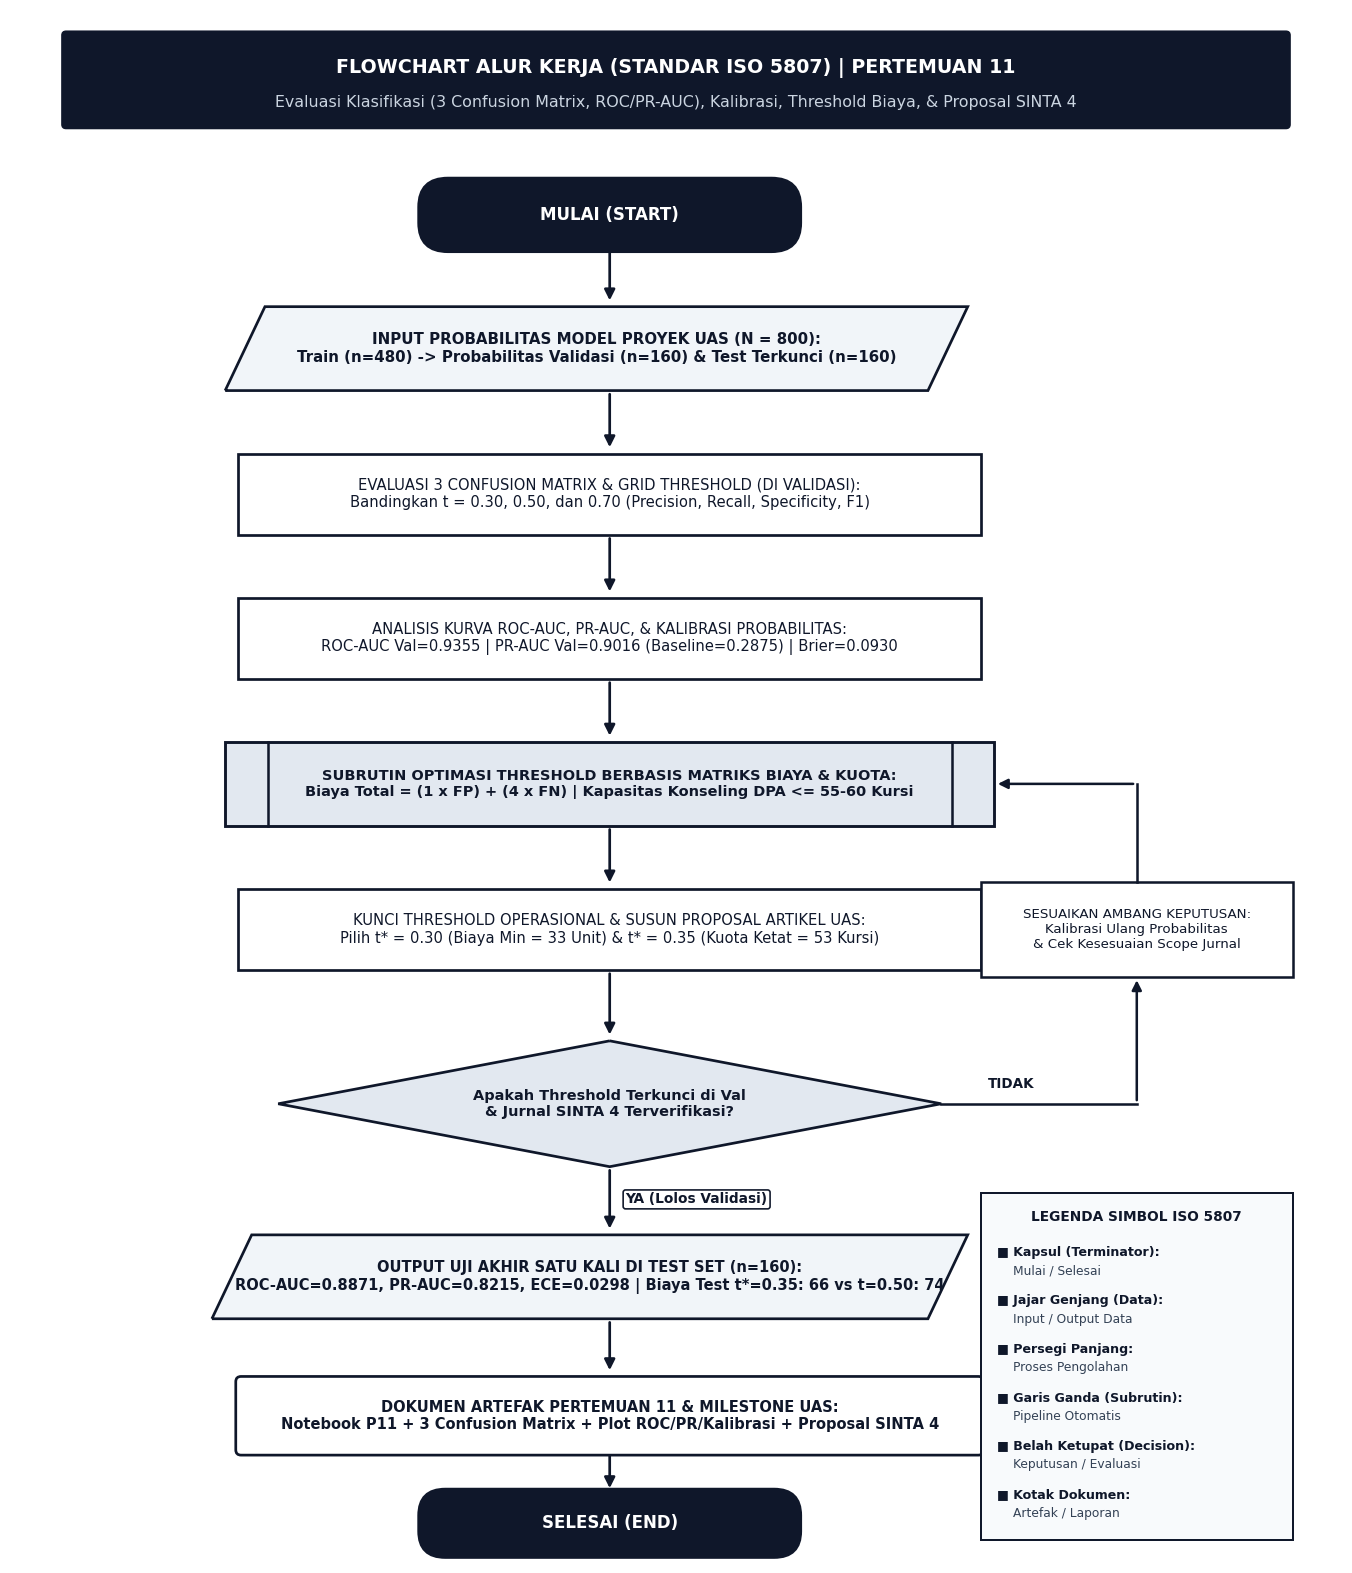

In [1]:
# Gambar Flowchart Alur Pengerjaan Pertemuan 11 (Standar Simbol ISO 5807)
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.path import Path

def gambar_flowchart_p11():
    fig, ax = plt.subplots(figsize=(10.5, 12.2), dpi=130)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 118)
    ax.axis("off")
    fig.patch.set_facecolor("white")

    # Header Banner
    header = mpatches.FancyBboxPatch((4, 109.5), 92, 6.8, boxstyle="round,pad=0.3", facecolor="#0f172a", edgecolor="#0f172a")
    ax.add_patch(header)
    ax.text(50, 113.8, "FLOWCHART ALUR KERJA (STANDAR ISO 5807) | PERTEMUAN 11", ha="center", va="center", color="white", fontsize=10.5, fontweight="bold")
    ax.text(50, 111.2, 'Evaluasi Klasifikasi (3 Confusion Matrix, ROC/PR-AUC), Kalibrasi, Threshold Biaya, & Proposal SINTA 4', ha="center", va="center", color="#cbd5e1", fontsize=8.8)

    steps = {'input': 'INPUT PROBABILITAS MODEL PROYEK UAS (N = 800):\nTrain (n=480) -> Probabilitas Validasi (n=160) & Test Terkunci (n=160)', 'proc1': 'EVALUASI 3 CONFUSION MATRIX & GRID THRESHOLD (DI VALIDASI):\nBandingkan t = 0.30, 0.50, dan 0.70 (Precision, Recall, Specificity, F1)', 'proc2': 'ANALISIS KURVA ROC-AUC, PR-AUC, & KALIBRASI PROBABILITAS:\nROC-AUC Val=0.9355 | PR-AUC Val=0.9016 (Baseline=0.2875) | Brier=0.0930', 'subroutine': 'SUBRUTIN OPTIMASI THRESHOLD BERBASIS MATRIKS BIAYA & KUOTA:\nBiaya Total = (1 x FP) + (4 x FN) | Kapasitas Konseling DPA <= 55-60 Kursi', 'proc3': 'KUNCI THRESHOLD OPERASIONAL & SUSUN PROPOSAL ARTIKEL UAS:\nPilih t* = 0.30 (Biaya Min = 33 Unit) & t* = 0.35 (Kuota Ketat = 53 Kursi)', 'decision': 'Apakah Threshold Terkunci di Val\n& Jurnal SINTA 4 Terverifikasi?', 'revisi': 'SESUAIKAN AMBANG KEPUTUSAN:\nKalibrasi Ulang Probabilitas\n& Cek Kesesuaian Scope Jurnal', 'output': 'OUTPUT UJI AKHIR SATU KALI DI TEST SET (n=160):\nROC-AUC=0.8871, PR-AUC=0.8215, ECE=0.0298 | Biaya Test t*=0.35: 66 vs t=0.50: 74', 'dokumen': 'DOKUMEN ARTEFAK PERTEMUAN 11 & MILESTONE UAS:\nNotebook P11 + 3 Confusion Matrix + Plot ROC/PR/Kalibrasi + Proposal SINTA 4'}
    # y positions for 8 main nodes (start + 6 steps + end)
    ys = [103.0, 92.5, 81.0, 69.5, 58.0, 46.5, 34.5, 22.0, 11.5, 3.5]

    def draw_arrow(x1, y1, x2, y2):
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#0f172a", mutation_scale=12))

    # 1. MULAI
    term_start = mpatches.FancyBboxPatch((31, 100.2), 28, 4.8, boxstyle="round,pad=0.4,rounding_size=2.2", facecolor="#0f172a", edgecolor="#0f172a", lw=1.6)
    ax.add_patch(term_start)
    ax.text(45, 102.6, "MULAI (START)", ha="center", va="center", color="white", fontsize=9.2, fontweight="bold")
    draw_arrow(45, 100.2, 45, 95.8)

    # 2. INPUT DATA (Parallelogram)
    verts_in = [(16, 89.2), (69, 89.2), (72, 95.6), (19, 95.6), (16, 89.2)]
    ax.add_patch(mpatches.PathPatch(Path(verts_in), facecolor="#f1f5f9", edgecolor="#0f172a", lw=1.5))
    ax.text(44, 92.4, steps["input"], ha="center", va="center", color="#0f172a", fontsize=8.3, fontweight="bold")
    draw_arrow(45, 89.2, 45, 84.6)

    # 3. PROSES 1 (Rectangle)
    ax.add_patch(mpatches.Rectangle((17, 78.2), 56, 6.2, facecolor="white", edgecolor="#0f172a", lw=1.5))
    ax.text(45, 81.3, steps["proc1"], ha="center", va="center", color="#0f172a", fontsize=8.2)
    draw_arrow(45, 78.2, 45, 73.6)

    # 4. PROSES 2 (Rectangle)
    ax.add_patch(mpatches.Rectangle((17, 67.2), 56, 6.2, facecolor="white", edgecolor="#0f172a", lw=1.5))
    ax.text(45, 70.3, steps["proc2"], ha="center", va="center", color="#0f172a", fontsize=8.2)
    draw_arrow(45, 67.2, 45, 62.6)

    # 5. SUBRUTIN PIPELINE (Double-lined Rectangle)
    ax.add_patch(mpatches.Rectangle((16, 56.0), 58, 6.4, facecolor="#e2e8f0", edgecolor="#0f172a", lw=1.6))
    ax.plot([19.2, 19.2], [56.0, 62.4], color="#0f172a", lw=1.4)
    ax.plot([70.8, 70.8], [56.0, 62.4], color="#0f172a", lw=1.4)
    ax.text(45, 59.2, steps["subroutine"], ha="center", va="center", color="#0f172a", fontsize=8.0, fontweight="bold")
    draw_arrow(45, 56.0, 45, 51.4)

    # 6. PROSES 3 (Rectangle)
    ax.add_patch(mpatches.Rectangle((17, 45.0), 56, 6.2, facecolor="white", edgecolor="#0f172a", lw=1.5))
    ax.text(45, 48.1, steps["proc3"], ha="center", va="center", color="#0f172a", fontsize=8.2)
    draw_arrow(45, 45.0, 45, 39.8)

    # 7. DECISION (Diamond) + Loop Back Box
    verts_dec = [(45, 39.6), (70, 34.8), (45, 30.0), (20, 34.8), (45, 39.6)]
    ax.add_patch(mpatches.PathPatch(Path(verts_dec), facecolor="#e2e8f0", edgecolor="#0f172a", lw=1.5))
    ax.text(45, 34.8, steps["decision"], ha="center", va="center", color="#0f172a", fontsize=8.0, fontweight="bold")

    # Side Revision Box
    ax.add_patch(mpatches.Rectangle((73, 44.5), 23.5, 7.2, facecolor="white", edgecolor="#0f172a", lw=1.4))
    ax.text(84.75, 48.1, steps["revisi"], ha="center", va="center", color="#0f172a", fontsize=7.4)
    ax.plot([70, 84.75], [34.8, 34.8], color="#0f172a", lw=1.4)
    ax.annotate("", xy=(84.75, 44.5), xytext=(84.75, 34.8), arrowprops=dict(arrowstyle="-|>", lw=1.4, color="#0f172a", mutation_scale=11))
    ax.plot([84.75, 84.75], [51.7, 59.2], color="#0f172a", lw=1.4)
    ax.annotate("", xy=(74.0, 59.2), xytext=(84.75, 59.2), arrowprops=dict(arrowstyle="-|>", lw=1.4, color="#0f172a", mutation_scale=11))
    ax.text(73.5, 36.0, "TIDAK", fontsize=7.5, fontweight="bold", color="#0f172a")

    draw_arrow(45, 30.0, 45, 25.0)
    ax.text(46.2, 27.2, "YA (Lolos Validasi)", fontsize=7.6, fontweight="bold", color="#0f172a", bbox=dict(boxstyle="round,pad=0.18", facecolor="white", edgecolor="#0f172a", lw=0.9))

    # 8. OUTPUT EVALUASI (Parallelogram)
    verts_out = [(15, 18.4), (69, 18.4), (72, 24.8), (18, 24.8), (15, 18.4)]
    ax.add_patch(mpatches.PathPatch(Path(verts_out), facecolor="#f1f5f9", edgecolor="#0f172a", lw=1.5))
    ax.text(43.5, 21.6, steps["output"], ha="center", va="center", color="#0f172a", fontsize=8.1, fontweight="bold")
    draw_arrow(45, 18.4, 45, 14.2)

    # 9. DOKUMEN ARTEFAK (Document shape)
    ax.add_patch(mpatches.FancyBboxPatch((17, 8.2), 56, 5.6, boxstyle="round,pad=0.2,rounding_size=0.4", facecolor="white", edgecolor="#0f172a", lw=1.5))
    ax.text(45, 11.0, steps["dokumen"], ha="center", va="center", color="#0f172a", fontsize=8.1, fontweight="bold")
    draw_arrow(45, 8.2, 45, 5.2)

    # 10. SELESAI
    term_end = mpatches.FancyBboxPatch((31, 0.6), 28, 4.4, boxstyle="round,pad=0.4,rounding_size=2.0", facecolor="#0f172a", edgecolor="#0f172a", lw=1.6)
    ax.add_patch(term_end)
    ax.text(45, 2.8, "SELESAI (END)", ha="center", va="center", color="white", fontsize=9.2, fontweight="bold")

    # Legend Box
    ax.add_patch(mpatches.Rectangle((73, 1.5), 23.5, 26.5, facecolor="#f8fafc", edgecolor="#0f172a", lw=1.1))
    ax.text(84.75, 26.2, "LEGENDA SIMBOL ISO 5807", ha="center", va="center", fontsize=7.6, fontweight="bold", color="#0f172a")
    leg_items = [
        ("■ Kapsul (Terminator):", "Mulai / Selesai"),
        ("■ Jajar Genjang (Data):", "Input / Output Data"),
        ("■ Persegi Panjang:", "Proses Pengolahan"),
        ("■ Garis Ganda (Subrutin):", "Pipeline Otomatis"),
        ("■ Belah Ketupat (Decision):", "Keputusan / Evaluasi"),
        ("■ Kotak Dokumen:", "Artefak / Laporan"),
    ]
    y_leg = 23.2
    for title_l, desc_l in leg_items:
        ax.text(74.2, y_leg, title_l, fontsize=7.0, fontweight="bold", color="#0f172a")
        ax.text(75.4, y_leg - 1.4, desc_l, fontsize=6.8, color="#334155")
        y_leg -= 3.7

    plt.tight_layout()
    plt.show()

print("Flowchart Alur Pengerjaan Pertemuan 11 (Standar Simbol ISO 5807 — Monokrom):")
gambar_flowchart_p11()


## 🎯 1. Tujuan dan Produk Akhir

Setelah tugas ini, mahasiswa harus mampu menghasilkan:

- proposal artikel satu halaman
- verifikasi awal target jurnal
- matriks biaya FP/FN
- precision-recall beberapa threshold
- threshold rekomendasi
- rencana eksperimen artikel

## 📋 2. Skenario Tugas

Analisis threshold pada kasus klasifikasi, sekaligus tetapkan topik proyek UAS individual yang akan dikembangkan menjadi artikel target jurnal SINTA 4.

Tulis ulang konteks kasus dengan bahasa sendiri. Nyatakan keputusan yang dibantu, pihak yang menggunakan hasil, unit analisis, serta konsekuensi bila analisis salah.

## 🛠️ 3. Langkah Kerja Wajib

1. Definisikan kelas positif dan konsekuensi kesalahan.
2. Dapatkan probabilitas dari data validasi, bukan test.
3. Evaluasi beberapa threshold sesuai tujuan.
4. Tentukan threshold dan kunci sebelum test final.
5. Rumuskan pertanyaan riset, dataset, baseline, model, dan target jurnal.

Setiap keputusan harus disertai alasan. Tangkapan layar tanpa kode, angka tanpa sumber, atau kesimpulan tanpa bukti tidak dinilai sebagai analisis.

## 📌 4. Bukti yang Harus Tampak di Notebook

- kurva/tabel threshold
- matriks biaya
- threshold terpilih
- proposal
- bukti jurnal
- rencana waktu

Jika suatu bukti tidak relevan, jelaskan alasannya dan berikan pengganti yang setara.

## 📊 5. Rubrik Penilaian

| Komponen | Bobot |
|---|---:|
| Evaluasi threshold | 25 |
| Keputusan berbasis biaya | 20 |
| Kualitas proposal artikel | 25 |
| Kelayakan metode dan data | 20 |
| Bukti target jurnal | 10 |
| **Total** | **100** |

Nilai tinggi membutuhkan kode yang benar **dan** interpretasi yang sesuai. Notebook yang hanya berjalan tetapi tidak menjelaskan arti hasil belum memenuhi capaian.

## 👤 6. Identitas Mahasiswa

Isi identitas dan pernyataan kasus sebelum mulai bekerja.

In [2]:
identitas = {
    "nama": "Fadli Hifziansyah",
    "nim": "241730042",
    "kelas": "5 INF B",
    "judul_tugas": "TUGAS_P11_Evaluasi_Klasifikasi_Threshold_Kalibrasi_dan_Proposal_Artikel_UAS_SINTA4",
    "sumber_data": (
        "UCI Machine Learning Repository — Predict Students' Dropout and Academic Success "
        "(Realinho et al., 2022; DOI: 10.24432/C5TG7T / Zenodo: 10.5281/zenodo.5777339, CC BY 4.0) "
        "& Dataset Proyek UAS SIAKAD-LMS Prodi Informatika (N = 800 Mahasiswa Unik)"
    ),
    "tanggal_pengerjaan": "16 November 2026",
}
identitas

{'nama': 'Fadli Hifziansyah',
 'nim': '241730042',
 'kelas': '5 INF B',
 'judul_tugas': 'TUGAS_P11_Evaluasi_Klasifikasi_Threshold_Kalibrasi_dan_Proposal_Artikel_UAS_SINTA4',
 'sumber_data': "UCI Machine Learning Repository — Predict Students' Dropout and Academic Success (Realinho et al., 2022; DOI: 10.24432/C5TG7T / Zenodo: 10.5281/zenodo.5777339, CC BY 4.0) & Dataset Proyek UAS SIAKAD-LMS Prodi Informatika (N = 800 Mahasiswa Unik)",
 'tanggal_pengerjaan': '16 November 2026'}

## ⚙️ 7. Persiapan Lingkungan

Jalankan sel berikut. Tambahkan pustaka hanya bila benar-benar digunakan. Jangan menyimpan output besar, data pribadi, token, kata sandi, atau kredensial di notebook.

In [3]:
# Instalasi hanya jika pustaka belum tersedia:
# %pip install -q pandas numpy scikit-learn matplotlib seaborn
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GroupKFold, TimeSeriesSplit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score
)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 120)
print("Lingkungan siap. SEED =", SEED)

Lingkungan siap. SEED = 42


## 📖 Kajian Teori dan Pemahaman Konsep (Pertemuan 11 — Evaluasi Klasifikasi, Threshold, Kalibrasi, & Biaya Kesalahan)

> 💡 **Panduan Membaca Bagian Ini:**  
> Pada Pertemuan 11 ini, kita mempelajari bahwa model klasifikasi sebenarnya mengeluarkan **angka peluang risiko (probabilitas `0,00` s.d. `1,00`)**, dan kitalah yang harus menentukan **batas ambang keputusan (*threshold*)** paling bijak berdasarkan biaya kesalahan serta kapasitas bimbingan DPA. Berikut adalah **10 konsep utama Pertemuan 11** yang dijelaskan melalui **6 komponen** menggunakan bahasa mahasiswa yang sederhana dan mudah dipahami oleh orang awam.  
> *(Catatan penting: Contoh angka pada bagian analogi di bawah hanyalah ilustrasi untuk mempermudah pemahaman konsep, bukan hasil dari dataset praktikum).*

### 🔹 1. Confusion Matrix (Matriks Kebingungan: TP, FP, FN, TN)

* **1. Pengertian:**  
  Confusion Matrix adalah tabel silang berukuran $2 \times 2$ yang mencocokkan kondisi asli mahasiswa di lapangan dengan hasil tebakan model pada suatu batas *threshold* tertentu, terbagi menjadi 4 kotak: **True Positive (TP)**, **False Positive (FP)**, **False Negative (FN)**, dan **True Negative (TN)**.

* **2. Tujuan dan Fungsi:**  
  Membedah jenis kesalahan model secara jujur: apakah model kita terlalu sering salah panggil mahasiswa yang sebenarnya aman (`FP` tinggi), atau justru sering kecolongan melewatkan mahasiswa yang benar-benar putus studi (`FN` tinggi).

* **3. Analogi Kehidupan Sehari-hari:**  
  Bayangkan penjaga pintu perpustakaan dengan alat pendeteksi buku yang belum dipinjam: **TP** = alat berbunyi saat memang ada buku yang belum discan; **FP** = alat berbunyi palsu padahal mahasiswa tidak membawa buku perpustakaan; **FN** = alat diam saja padahal ada buku yang terbawa keluar; **TN** = alat tenang saat mahasiswa memang tidak membawa buku.

* **4. Cara Kerja Sederhana dalam Machine Learning:**  
  Pada setiap *threshold* $t$ (misalnya `0,30`, `0,50`, dan `0,70`), jika peluang risiko mahasiswa $\hat{p}_i \ge t$ maka ditebak `1` (Berisiko), lalu dicocokkan dengan label asli $y_i \in \{0, 1\}$ untuk menghitung jumlah `TN, FP, FN, TP`.

* **5. Contoh Penerapan dalam Praktikum:**  
  Pada Sel Kode #4 dan Panel A visualisasi (partisi Validasi $n=160$, terdiri dari 114 bertahan dan 46 *dropout*): pada **$t=0{,}30$** tercatat `TN=97, FP=17, FN=4, TP=42`; pada **$t=0{,}50$** tercatat `TN=112, FP=2, FN=16, TP=30`; dan pada **$t=0{,}70$** tercatat `TN=114, FP=0, FN=31, TP=15`.

* **6. Hubungannya dengan Proyek pada Pertemuan Ini:**  
  Tanpa melihat *Confusion Matrix*, DPA tidak akan menyadari bahwa memakai *threshold* standar `0,50` ternyata membuat **16 dari 46 mahasiswa *dropout* terlewat (`FN = 16`)**, sedangkan menurunkan *threshold* ke `0,30` berhasil memangkas jumlah kecolongan menjadi hanya **4 mahasiswa (`FN = 4`)**.


### 🔹 2. Precision vs. Recall (Tarik-Ulur Ketepatan Panggilan vs. Daya Tangkap)

* **1. Pengertian:**  
  **Precision** ($\frac{\text{TP}}{\text{TP} + \text{FP}}$) mengukur dari seluruh mahasiswa yang dipanggil konseling oleh model, berapa persen yang benar-benar mengalami *dropout*. **Recall / Sensitivity** ($\frac{\text{TP}}{\text{TP} + \text{FN}}$) mengukur dari seluruh mahasiswa yang pada kenyataannya *dropout*, berapa persen yang berhasil ditangkap oleh model.

* **2. Tujuan dan Fungsi:**  
  Membantu kita menyeimbangkan dua kepentingan yang saling tarik-menarik: ingin menangkap sebanyak mungkin mahasiswa berisiko (*Recall* tinggi) sekaligus menjaga agar panggilan konseling tidak banyak yang salah sasaran (*Precision* terjaga).

* **3. Analogi Kehidupan Sehari-hari:**  
  *Contoh sesuai Latihan Analitis #2 dosen (ilustrasi konsep):* Jika sistem memanggil 50 mahasiswa (`TP = 40` benar-benar *dropout* dan `FP = 10` ternyata aman), maka **Precision** sistem adalah $\frac{40}{40 + 10} = \frac{40}{50} = 0{,}80$ (**80%**). Artinya, 4 dari setiap 5 kursi konseling yang disiapkan DPA tepat sasaran.

* **4. Cara Kerja Sederhana dalam Machine Learning:**  
  Ketika *threshold* diturunkan (ke `0,30`), model lebih peka menebak positif sehingga **Recall naik tinggi** tetapi **Precision sedikit turun**. Sebaliknya ketika *threshold* dinaikkan (ke `0,70`), model menjadi sangat pemilih sehingga **Precision naik ke 100%** tetapi **Recall anjlok parah**.

* **5. Contoh Penerapan dalam Praktikum:**  
  Pada partisi Validasi ($n=160$), saat *threshold* digeser dari `0,30` $\rightarrow$ `0,50` $\rightarrow$ `0,70`, nilai **Recall** turun tajam dari **`0,9130` (91,30%)** $\rightarrow$ **`0,6522` (65,22%)** $\rightarrow$ **`0,3261` (32,61%)**, sedangkan **Precision** bergerak dari **`0,7119`** $\rightarrow$ **`0,9375`** $\rightarrow$ **`1,0000`**.

* **6. Hubungannya dengan Proyek pada Pertemuan Ini:**  
  Pada proyek peringatan dini *dropout* ini, kita tidak boleh membiarkan *Recall* jatuh ke 65% atau 32%, karena mahasiswa yang terlewat (*False Negative*) akan kehilangan kesempatan diselamatkan sebelum KRS Semester 2.


### 🔹 3. Specificity / True Negative Rate (Kemampuan Mengenali Mahasiswa Aman)

* **1. Pengertian:**  
  Specificity ($\frac{\text{TN}}{\text{TN} + \text{FP}}$) adalah persentase mahasiswa yang benar-benar bertahan aktif (`y = 0`) yang berhasil dikenali dengan tepat sebagai mahasiswa aman (`prediksi = 0`) oleh model.

* **2. Tujuan dan Fungsi:**  
  Menjaga agar sistem tidak memicu 'alarm palsu massal' yang memboroskan waktu kerja dosen wali dan menimbulkan kecemasan yang tidak perlu pada mahasiswa yang sebenarnya baik-baik saja.

* **3. Analogi Kehidupan Sehari-hari:**  
  Jika sebuah tes skrining terlalu sensitif sampai-sampai semua orang sehat dibilang sakit (*Specificity* = 0%), maka ruang konseling akan penuh sesak oleh mahasiswa yang sebenarnya aman sehingga mahasiswa yang benar-benar gawat justru tidak kebagian jadwal.

* **4. Cara Kerja Sederhana dalam Machine Learning:**  
  Specificity adalah kebalikan langsung dari tingkat alarm palsu (*False Positive Rate* / FPR): $\text{Specificity} = 1 - \text{FPR} = \frac{\text{TN}}{\text{TN} + \text{FP}}$.

* **5. Contoh Penerapan dalam Praktikum:**  
  Pada partisi Validasi ($n=160$, dengan 114 mahasiswa bertahan), saat *threshold* berada di `0,30`, `0,35`, `0,50`, dan `0,70`, nilai **Specificity** tercatat sangat terjaga yaitu **`0,8509` (97/114)**, **`0,8772` (100/114)**, **`0,9825` (112/114)**, dan **`1,0000` (114/114)**.

* **6. Hubungannya dengan Proyek pada Pertemuan Ini:**  
  Konsep ini menjawab Latihan Analitis #3 dosen: pada $t=0{,}30$ dan $t=0{,}35$, nilai *Specificity* masih di atas **85%–87%**, artinya mayoritas besar mahasiswa aman tetap dikenali dengan benar tanpa membebani kuota DPA.


### 🔹 4. F1-Score (Titik Keseimbangan Harmonik Precision dan Recall)

* **1. Pengertian:**  
  F1-Score adalah rata-rata harmonik dari *Precision* dan *Recall* ($2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$) yang memberikan nilai tinggi hanya jika *Precision* dan *Recall* sama-sama tinggi.

* **2. Tujuan dan Fungsi:**  
  Menjadi ukuran ringkas untuk mengecek pada rentang *threshold* mana model memiliki keseimbangan teknis terbaik antara daya tangkap dan ketepatan panggilan.

* **3. Analogi Kehidupan Sehari-hari:**  
  Seperti nilai akhir praktikum yang menggabungkan nilai kuis dan nilai proyek dengan rumus harmonik: kalau salah satu nilainya jatuh mendekati nol, nilai akhirnya ikut jatuh.

* **4. Cara Kerja Sederhana dalam Machine Learning:**  
  Program menghitung F1-Score untuk setiap kandidat *threshold* (`0,20` s.d. `0,80`) di partisi Validasi.

* **5. Contoh Penerapan dalam Praktikum:**  
  Pada tabel *trade-off threshold* di partisi Validasi, F1-Score mencapai nilai yang sangat tinggi pada rentang **$t=0{,}30$ (`0,8000`)**, **$t=0{,}35$ (`0,7879`)**, dan **$t=0{,}40$ (`0,8090`)**, lebih unggul dibandingkan $t=0{,}50$ (**`0,7692`**) maupun $t=0{,}70$ (**`0,4918`**).

* **6. Hubungannya dengan Proyek pada Pertemuan Ini:**  
  Menariknya, pada data kita, menurunkan *threshold* dari `0,50` ke `0,30`–`0,40` tidak hanya menurunkan biaya kesalahan, tetapi juga **menaikkan F1-Score** dari `0,7692` menjadi `0,8000–0,8090`!


### 🔹 5. Kurva ROC dan ROC-AUC (Daya Pisah Urutan Peringkat Lintas Threshold)

* **1. Pengertian:**  
  Kurva ROC (*Receiver Operating Characteristic*) adalah grafik yang memplot **True Positive Rate (Recall)** di sumbu tegak melawan **False Positive Rate ($1 - \text{Specificity}$)** di sumbu mendatar untuk seluruh kemungkinan *threshold* dari `0,00` hingga `1,00`. **ROC-AUC** adalah luas area di bawah kurva tersebut.

* **2. Tujuan dan Fungsi:**  
  Mengukur kemampuan daya pisah (*diskriminasi*) model secara menyeluruh sebelum kita mengunci satu angka *threshold* tertentu.

* **3. Analogi Kehidupan Sehari-hari:**  
  Jika kita meminta model mengurutkan mahasiswa dari yang paling berisiko sampai paling aman, nilai ROC-AUC sebesar `0,9355` berarti jika kita mengambil 1 mahasiswa *dropout* dan 1 mahasiswa bertahan secara acak, ada peluang **93,55%** model memberikan skor risiko yang lebih tinggi kepada mahasiswa yang *dropout*.

* **4. Cara Kerja Sederhana dalam Machine Learning:**  
  Garis diagonal dari `(0,0)` ke `(1,1)` melambangkan tebakan koin acak dengan **baseline $\text{ROC-AUC} = 0{,}5000$**. Makin melengkung kurva ke pojok kiri atas (mendekati `1,0000`), makin tajam daya pisah model.

* **5. Contoh Penerapan dalam Praktikum:**  
  Pada partisi Validasi ($n=160$), model *Logistic Regression Terkalibrasi* proyek UAS kita meraih **ROC-AUC = `0,9355`** (dan pada partisi Test Final $n=160$ meraih **ROC-AUC = `0,8871`**), mengungguli *Pruned Decision Tree* (`ROC-AUC Val = 0,8051`, `Test = 0,7282`).

* **6. Hubungannya dengan Proyek pada Pertemuan Ini:**  
  Walaupun ROC-AUC sangat berguna untuk mengukur kualitas urutan risiko secara global, kita wajib menyandingkannya dengan kurva PR-AUC karena jumlah kelas di data kita tidak seimbang.


### 🔹 6. Kurva Precision–Recall (PR Curve) dan Baseline PR-AUC pada Data Timpang

* **1. Pengertian:**  
  Kurva Precision–Recall adalah grafik yang memplot **Precision** di sumbu tegak melawan **Recall** di sumbu mendatar untuk setiap perubahan *threshold*. **PR-AUC** adalah luas area di bawah kurva Precision–Recall.

* **2. Tujuan dan Fungsi:**  
  Memberikan gambaran evaluasi yang jauh lebih jujur dan peka pada dataset dengan kelas tidak seimbang (*class imbalance*) karena fokus langsung pada kinerja kelas positif tanpa terpengaruh oleh banyaknya jumlah `True Negative` ([Saito & Rehmsmeier, 2015](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0118432)).

* **3. Analogi Kehidupan Sehari-hari:**  
  Seperti menilai ketepatan tim pencari barang hilang di gedung besar: kita tidak menghitung berapa ribu ruangan kosong yang berhasil dilewati (`TN`), melainkan fokus pada berapa persen barang hilang yang ditemukan (*Recall*) dan berapa persen laporan temuan yang benar (*Precision*).

* **4. Cara Kerja Sederhana dalam Machine Learning:**  
  Berbeda dengan ROC yang baseline acaknya selalu `0,50`, **baseline PR-AUC sama dengan prevalensi (proporsi) kelas positif di dalam dataset**, yaitu $\frac{P}{P+N}$.

* **5. Contoh Penerapan dalam Praktikum:**  
  Konsep ini menjawab Latihan Analitis #4 dosen: karena di dataset kita terdapat 46 mahasiswa *dropout* dari 160 mahasiswa di Validasi ($230/800$ total), maka **baseline PR-AUC adalah `0,2875` (28,75%)**. Model kita berhasil meraih **PR-AUC Validasi = `0,9016`** (dan **PR-AUC Test = `0,8215`**), lebih dari 3 kali lipat di atas baseline!

* **6. Hubungannya dengan Proyek pada Pertemuan Ini:**  
  Tampilan berdampingan antara kurva ROC dan kurva Precision–Recall pada Panel B visualisasi membuktikan ketajaman model kita khusus pada kelompok mahasiswa berisiko.


### 🔹 7. Diskriminasi vs. Kalibrasi Probabilitas (Reliability Diagram & Brier Score)

* **1. Pengertian:**  
  **Diskriminasi** adalah kemampuan model membedakan dan mengurutkan siapa yang lebih berisiko daripada yang lain (diukur dengan ROC-AUC/PR-AUC). **Kalibrasi probabilitas** adalah seberapa jujur dan akurat angka peluang $\hat{p}$ yang dikeluarkan model dibandingkan kenyataan di lapangan (diukur dengan *Reliability Diagram*, *Brier Score*, dan *Expected Calibration Error* / ECE).

* **2. Tujuan dan Fungsi:**  
  Memastikan bahwa ketika model mengeluarkan angka peluang risiko `0,30` (30%), memang benar sekitar 25%–30% dari mahasiswa dengan skor tersebut mengalami *dropout*—bukan angkanya melambung tinggi padahal kenyataannya jauh lebih rendah.

* **3. Analogi Kehidupan Sehari-hari:**  
  Bayangkan dua peramal cuaca: Peramal A selalu bilang 'peluang hujan 90%' saat mendung dan 'peluang hujan 50%' saat agak berawan. Urutannya memang benar (saat mendung angkanya lebih tinggi $\rightarrow$ **diskriminasi bagus**), tetapi angkanya terlalu dibesar-besarkan karena saat agak berawan sebenarnya hanya 3% yang turun hujan (**kalibrasi buruk**). Peramal B memberikan angka peluang yang pas dengan persentase kejadian hujan sebenarnya (**diskriminasi bagus DAN kalibrasi bagus**).

* **4. Cara Kerja Sederhana dalam Machine Learning:**  
  Kita membagi prediksi probabilitas di Validasi ke dalam 5 kelompok rentang (*bin* `[0.0–0.2]` s.d. `[0.8–1.0]`), memplot rata-rata probabilitas prediksi vs. proporsi *dropout* aktual (*Reliability Diagram*), serta menghitung **Brier Score** ($\frac{1}{N}\sum (\hat{p}_i - y_i)^2$, makin kecil makin baik).

* **5. Contoh Penerapan dalam Praktikum:**  
  Pada Sel Kode #5 dan Panel C visualisasi, terbukti nyata perbedaan keduanya: model `LogisticRegression(class_weight='balanced')` memiliki **diskriminasi yang sangat tinggi (`ROC-AUC Val = 0,9378`)**, tetapi karena bobot kelasnya digandakan saat latihan, probabilitasnya terlalu tinggi di rentang menengah (pada bin `[0.2, 0.4]` rata-rata prediksi `0,3086` padahal kejadian aktual hanya `0,0294`; **Brier Score Val = `0,1123`**, **ECE Val = `0,1365`**; **ECE Test = `0,1216`**). Sebaliknya, **Logistic Regression Terkalibrasi (Natural/Platt Scaling)** memiliki diskriminasi setara (`ROC-AUC Val = 0,9355`, `Test = 0,8871`) namun jauh lebih terkalibrasi dengan **Brier Score Val terbaik = `0,0930`** (**ECE Val = `0,0865`**) dan pada partisi Test mencapai **Brier Score = `0,1126`** dengan **ECE Test sangat presisi = `0,0298` (2,98%)**!

* **6. Hubungannya dengan Proyek pada Pertemuan Ini:**  
  Pembedahan ini menjawab Latihan Analitis #5 dosen sekaligus menjelaskan mengapa kita wajib menggunakan **probabilitas yang sudah terkalibrasi** saat menentukan *threshold* berbasis matriks biaya.


### 🔹 8. Matriks Biaya Kesalahan (Cost Matrix FP vs. FN) dan Kapasitas Tindak Lanjut

* **1. Pengertian:**  
  Matriks biaya kesalahan adalah tabel bobot kerugian nyata yang menetapkan berapa harga kerugian dari satu *False Positive* ($C_{\text{FP}}$) dibandingkan satu *False Negative* ($C_{\text{FN}}$), dikombinasikan dengan batas kuota kapasitas intervensi organisasi.

* **2. Tujuan dan Fungsi:**  
  Mengubah pemilihan *threshold* dari sekadar menebak angka bawaan `0,50` menjadi keputusan berbasis biaya dan kapasitas nyata di program studi.

* **3. Analogi Kehidupan Sehari-hari:**  
  Bagi kampus, memanggil 1 mahasiswa aman untuk ngobrol perwalian selama 30 menit ($C_{\text{FP}} = 1$ unit biaya, setara $\approx \text{Rp}150.000$ beban waktu pembinaan) jauh lebih ringan dibandingkan membiarkan 1 mahasiswa berisiko terlewat tanpa bantuan sampai putus kuliah ($C_{\text{FN}} = 4$ unit biaya, setara $\approx \text{Rp}600.000$ dampak institusional & akademik).

* **4. Cara Kerja Sederhana dalam Machine Learning:**  
  Untuk setiap kandidat *threshold* $t$, kita menghitung $\text{Total Biaya}(t) = (1 \times \text{FP}_t) + (4 \times \text{FN}_t)$ pada partisi Validasi ($n=160$), serta memeriksa apakah jumlah panggilan $(\text{TP}_t + \text{FP}_t)$ sesuai dengan kapasitas kuota bimbingan DPA (sekitar 50–60 mahasiswa di partisi validasi/uji).

* **5. Contoh Penerapan dalam Praktikum:**  
  Pada Sel Kode #6 dan Panel D visualisasi: jika memakai *threshold* standar **$t = 0{,}50$**, terdapat `2 FP` namun kecolongan **`16 FN`** sehingga **Total Biaya = `66` unit (Rp9,90 juta)**; pada **$t = 0{,}70$**, kecolongan **`31 FN`** sehingga **Total Biaya melonjak ke `124` unit (Rp18,60 juta)**! Sebaliknya, pada **$t = 0{,}30$ (Threshold Operasional Biaya Minimum)**, jumlah kecolongan ditekan menjadi hanya **`4 FN`** (`Recall = 91,30%`, `FP = 17`, `F1 = 0,8000`, panggilan = `59` mahasiswa) sehingga **Total Biaya mencapai titik paling minimum yaitu `33` unit (Rp4,95 juta — hemat 50% biaya dibanding $t=0{,}50$!)**. Apabila kuota DPA dibatasi ketat maksimal 55 mahasiswa, maka **$t = 0{,}35$** memanggil **53 mahasiswa** dengan **Total Biaya = `42` unit (Rp6,30 juta, Recall `84,78%`)**.

* **6. Hubungannya dengan Proyek pada Pertemuan Ini:**  
  Analisis matriks biaya ini membuktikan secara kuantitatif mengapa menggeser *threshold* dari `0,50` ke **`0,30` (atau `0,35` pada kuota ketat)** menyelamatkan 12 mahasiswa tambahan dari risiko *dropout* sekaligus menghemat separuh biaya kesalahan.


### 🔹 9. Disiplin Kunci Threshold di Validasi Sebelum Evaluasi Akhir di Test

* **1. Pengertian:**  
  Aturan penguncian *threshold* berarti seluruh pencarian dan pembandingan angka *threshold* (`0,20` s.d. `0,80`) hanya boleh dilakukan pada **partisi Validasi ($n=160$)**; setelah *threshold* operasional dipilih dan dikunci, barulah angka tersebut diuji satu kali pada **partisi Test Final ($n=160$)**.

* **2. Tujuan dan Fungsi:**  
  Mencegah *threshold leakage* (kecurangan memilih *threshold* karena mengintip skor di data *Test*).

* **3. Analogi Kehidupan Sehari-hari:**  
  Seperti mengatur bidikan teropong senapan di lapangan tembak latihan (*Validation*): setelah setelan bidikannya dikunci, barulah dipakai menembak satu kali di papan nilai lomba resmi (*Test*).

* **4. Cara Kerja Sederhana dalam Machine Learning:**  
  Kita mengunci rekomendasi *threshold* dari Validasi ($t^* = 0{,}30$ untuk biaya minimum dan $t^* = 0{,}35$ untuk kuota ketat $\le 55$ kursi, beserta pembanding $0{,}50$ dan $0{,}70$), lalu mengevaluasinya pada `y_test` dan `proba_test` ($n=160$).

* **5. Contoh Penerapan dalam Praktikum:**  
  Saat diuji pada partisi *Test Final* ($n=160$), kedua *threshold* operasional tersebut terbukti unggul konsisten: pada **$t = 0{,}30$** memanggil **50 mahasiswa** (muat di dalam kuota DPA!) dengan **Recall Test = `0,7174` (33/46 kasus tertangkap)**, **Specificity = `0,8509`**, **F1 = `0,6875`**, dan **Total Biaya = `69` unit**; dan pada **$t = 0{,}35$** memanggil **47 mahasiswa** dengan **Precision = `0,7021`**, **Recall = `0,7174`**, **Specificity = `0,8772`**, **F1 = `0,7097`**, dan **Total Biaya Test paling rendah = `66` unit (Rp9,90 juta)**—mengalahkan $t=0{,}50$ (`Biaya = 74 unit`) dan $t=0{,}70$ (`Biaya = 106 unit`, `Recall` hanya `43,48%`).

* **6. Hubungannya dengan Proyek pada Pertemuan Ini:**  
  Konsistensi antara hasil Validasi dan hasil Test Final membuktikan bahwa pemilihan *threshold* berbasis biaya ini benar-benar tahan uji pada data baru.


### 🔹 10. Proposal Artikel Ilmiah UAS & Verifikasi Target Jurnal SINTA 4

* **1. Pengertian:**  
  Proposal artikel ilmiah UAS adalah rancangan penelitian terstruktur satu halaman yang merangkum judul, rumusan masalah (*research questions*), dataset berlisensi terbuka, model & baseline pembanding, metrik evaluasi, jadwal eksperimen, serta bukti verifikasi jurnal nasional terakreditasi **SINTA 4**.

* **2. Tujuan dan Fungsi:**  
  Menjadi jembatan langsung dari tugas praktikum mingguan (Pertemuan 1–11) menuju naskah publikasi ilmiah tugas akhir mata kuliah (UAS).

* **3. Analogi Kehidupan Sehari-hari:**  
  Seperti menyusun cetak biru (*blueprint*) bangunan lengkap dengan alamat lahan resmi yang sudah dicek sertifikatnya sebelum mulai membangun rumah.

* **4. Cara Kerja Sederhana dalam Machine Learning:**  
  Kita menyusun struktur artikel mengikuti format IMRaD (*Introduction, Method, Results, and Discussion*) dan memverifikasi profil jurnal target langsung pada pangkalan data resmi **SINTA Kemdiktisaintek** serta laman **Open Journal Systems (OJS)** penerbit.

* **5. Contoh Penerapan dalam Praktikum:**  
  Pada Bagian 11 notebook ini, kita menyertakan proposal lengkap beserta bukti verifikasi tiga jurnal SINTA 4 bidang Informatika: **JIKO (UTDI — SINTA 4, ID SINTA 103)** sebagai target utama, serta **KOMPUTA (UNIKOM — SINTA 4, ID SINTA 8075)** dan **Infotek (Universitas Hamzanwadi — SINTA 4, SK 225/E/KPT/2022)** sebagai target alternatif.

* **6. Hubungannya dengan Proyek pada Pertemuan Ini:**  
  Dengan rancangan proposal dan target jurnal SINTA 4 yang sudah terverifikasi ini, pengerjaan proyek UAS pada Pertemuan 12–16 memiliki arah yang jelas dan terukur.


## 🔍 8. Rumusan Analisis

Jawab pada sel Markdown baru:

1. Apa masalah dan keputusan yang dibantu?
2. Apa unit analisis dan kapan keluaran dibuat?
3. Data apa yang tersedia pada saat keputusan?
4. Apa baseline dan metrik utama?
5. Apa risiko bila hasil keliru atau disalahgunakan?

### 📝 Jawaban Rumusan Analisis, Strategi Pemilihan Threshold, & 5 Latihan Analitis Pertemuan 11

> 💡 **Inti Bagian Ini:**  
> Bagian ini menjawab secara berurutan **5 pertanyaan Rumusan Analisis** pada template tugas sekaligus membahas **5 soal Latihan Analitis** dari dosen dengan bahasa yang lugas dan contoh perhitungan yang jelas.

---

#### A. Jawaban 5 Pertanyaan Rumusan Analisis (Langkah Kerja 1–8)

##### 1. Konteks Kasus, Unit Analisis, Kelas Positif, dan Keputusan yang Dibantu (Langkah 1)
* **Konteks Masalah & Pengguna Hasil:** Pada Program Studi Informatika, mahasiswa tingkat pertama yang mengalami kesulitan adaptasi akademik atau kendala biaya kuliah di Semester 1 sangat rentan mengalami putus studi (*dropout*) atau menjadi non-aktif pada tahun akademik kedua. Hasil prediksi dari model klasifikasi proyek UAS ini digunakan oleh **Dosen Pembimbing Akademik (DPA), Ketua Program Studi Informatika, dan Unit Bimbingan Konseling** untuk menyusun **daftar panggilan konseling perwalian dini, penugasan kelas klinik algoritma/pemrograman dasar, serta rujukan evaluasi keringanan cicilan UKT** sebelum masa pengisian KRS Semester 2 ditutup.
* **Unit Analisis & Titik Waktu Keputusan:** Satu baris data mewakili **satu mahasiswa aktif tingkat pertama** ($N = 800$ mahasiswa unik setelah menghapus 12 baris duplikat dari 812 baris mentah SIAKAD). Prediksi dilakukan tepat pada **H+3 setelah nilai ujian akhir Semester 1 dikunci di SIAKAD**, sebelum perkuliahan Semester 2 dimulai.
* **Definisi Kelas Positif ($y = 1$) & Prevalensi:**
  * **Kelas Positif ($y = 1$ / `status_dropout == 1`):** Mahasiswa yang mengalami **Putus Studi (*Dropout*) atau Non-Aktif pada Tahun Akademik Kedua**. Jumlahnya sebanyak **230 dari 800 mahasiswa (`28,75%`)**. Pada pembagian berstrata (`SEED = 42`), terdapat **138 kasus positif di Train ($n = 480$)**, **46 kasus positif di Validation ($n = 160$)**, dan **46 kasus positif di Test Final ($n = 160$)**.
  * **Kelas Negatif ($y = 0$ / `status_dropout == 0`):** Mahasiswa yang **Bertahan Aktif Kuliah**, berjumlah **570 dari 800 mahasiswa (`71,25%`)** (114 mahasiswa di Validation dan 114 mahasiswa di Test Final).

##### 2. Mengapa Probabilitas Diambil dari Data Validasi (Bukan Data Test)? (Langkah 2 & 3)
* Saat kita menggeser nilai *threshold* (misalnya membandingkan `0,30`, `0,50`, dan `0,70` atau mencari *threshold* dengan biaya kesalahan paling murah), proses tersebut sebenarnya adalah bagian dari **penyetelan keputusan model (*hyperparameter / decision-rule tuning*)**.
* Jika kita memilih *threshold* dengan cara melihat nilai metrik di data *Test*, maka kita melakukan kecurangan metodologi yang disebut **kebocoran ambang batas (*threshold leakage*)**—model seolah-olah sudah tahu kunci jawaban ujian akhir lalu menyesuaikan batas lulusnya agar terlihat bagus di ujian tersebut.
* Oleh sebab itu, sesuai aturan emas Pembelajaran Mesin: **seluruh evaluasi kandidat threshold, kurva ROC/PR eksploratif, pemeriksaan kalibrasi, dan pencarian biaya minimum dilakukan murni menggunakan probabilitas dari partisi Validasi ($n = 160$)**. Setelah satu *threshold* operasional dipilih dan dikunci, barulah angka *threshold* tersebut diuji satu kali pada **partisi Test Final ($n = 160$)**.

##### 3. Data yang Tersedia pada Saat Keputusan & Pencegahan Data Leakage
* Seluruh **12 fitur prediktor** yang masuk ke dalam `Pipeline` telah diverifikasi tersedia secara sah pada akhir Semester 1:
  * **9 Fitur Numerik:** `ip_sem1`, `sks_lulus_sem1`, `sks_diambil_sem1`, `rasio_kehadiran_sem1`, `login_lms_per_minggu`, `rasio_tugas_tepat_waktu`, `jam_kerja_per_minggu`, `skor_seleksi_masuk`, dan `usia_saat_masuk`.
  * **3 Fitur Kategorikal / Biner:** `jalur_masuk` (`SNBP`, `SNBT`, `Mandiri`), `golongan_ukt` (`Gol_1` s.d. `Gol_5`), dan `status_ukt_lunas` (`1` = Lunas, `0` = Menunggak).
* Kolom pengenal (`student_id`), atribut struktur grup/waktu (`kelompok_kelas_dpa`, `urutan_registrasi`), serta kolom masa depan Semester 2 (`ip_sem2_bocoran`) **dikeluarkan sepenuhnya** dari matriks fitur pelatihan. Seluruh tahap penambalan nilai kosong (`SimpleImputer`) dan penyamaan skala (`StandardScaler` serta `OneHotEncoder`) dibungkus di dalam `Pipeline` yang di-`fit` hanya pada partisi *Train* ($n = 480$).

##### 4. Baseline, Metrik Evaluasi, dan Matriks Biaya Kesalahan (Langkah 4–8)
* **Baseline Pembanding:**
  1. **Baseline ROC-AUC:** Garis diagonal tebakan acak dengan nilai **$	ext{ROC-AUC} = 0{,}5000$**.
  2. **Baseline PR-AUC:** Garis mendatar sesuai proporsi (prevalensi) kelas positif di populasi yaitu **$	ext{PR-AUC} = rac{46}{160} = 0{,}2875$ (28,75%)**.
  3. **Model Pembanding Pohon Keputusan:** `DecisionTreeClassifier(max_depth=4)` yang telah dipangkas agar tidak *overfitting*.
* **Matriks Biaya Kesalahan (*Cost Matrix* FP vs. FN) & Kapasitas Tindak Lanjut:**
  * **False Positive (FP — Mahasiswa aman tetapi dipanggil konseling):** Menimbulkan beban waktu wawancara DPA sekitar 30 menit dan kuota modul pendampingan dasar. Kita tetapkan bobot biaya **$C_{	ext{FP}} = 1	ext{ unit biaya}$** (setara estimasi operasional **$	ext{Rp}150.000$** per mahasiswa).
  * **False Negative (FN — Mahasiswa berisiko tinggi *dropout* tetapi terlewat/tidak dipanggil):** Konsekuensinya jauh lebih berat karena mahasiswa tidak mendapat pertolongan dini hingga akhirnya berhenti kuliah (merugikan masa depan mahasiswa, menurunkan akreditasi ketepatan waktu lulus prodi, dan menghilangkan pendapatan UKT semester berikutnya). Kita tetapkan bobot biaya **$C_{	ext{FN}} = 4	ext{ unit biaya}$** (rasio asimetris $4 : 1$, setara estimasi kerugian komposit minimal **$	ext{Rp}600.000$** per mahasiswa).
  * **Kapasitas Tindak Lanjut DPA:** Pada setiap sampel kohort 160 mahasiswa (1/5 angkatan), tim DPA memiliki kapasitas konseling tatap muka sekitar **50–60 kursi mahasiswa** (atau maksimal **55 kursi** bila jadwal awal semester sangat padat).

##### 5. Risiko Bila Hasil Prediksi atau Threshold Keliru / Disalahgunakan
* Jika *threshold* dipasang terlalu tinggi (misalnya `0,70`), sistem akan mengalami **buta risiko (*low recall* `32,61%`)**: 31 dari 46 mahasiswa *dropout* di Validasi tidak terdeteksi sama sekali.
* Sebaliknya, jika *threshold* dipasang terlalu rendah (misalnya `0,15`), panggilan palsu (`FP`) akan membludak melebihi kapasitas dosen wali.
* Selain itu, skor peluang *dropout* **tidak boleh digunakan untuk melabeli mahasiswa secara negatif atau memberi sanksi akademik**, melainkan wajib dibingkai secara internal bagi DPA sebagai **Indeks Prioritas Dukungan Akademik dan Kesejahteraan Mahasiswa**.

---

#### B. Jawaban Lengkap 5 Pertanyaan Latihan Analitis Dosen

##### 🔹 Soal Analitis 1: Kapan *Recall* perlu diprioritaskan?
* **Jawaban:** Metrik **Recall** ($rac{	ext{TP}}{	ext{TP} + 	ext{FN}}$) wajib diprioritaskan ketika **biaya atau dampak buruk akibat melewatkan satu kasus positif (*False Negative* / FN) jauh lebih berbahaya dan lebih mahal daripada biaya akibat memeriksa satu alarm palsu (*False Positive* / FP)**.
* **Contoh Nyata:**
  1. **Pada Proyek UAS Kita (Deteksi Dini *Dropout* Mahasiswa):** Melewatkan seorang mahasiswa yang sedang kesulitan berat (`FN`) membuat ia tidak dibantu DPA hingga akhirnya benar-benar putus kuliah, sedangkan salah memanggil mahasiswa yang ternyata aman (`FP`) hanya membutuhkan sesi obrolan perwalian singkat selama 20–30 menit.
  2. **Di Bidang Medis & Keamanan:** Skrining awal penyakit ganas (seperti kanker) atau deteksi transaksi penipuan rekening bank (*fraud detection*), di mana lolosnya satu kasus positif berakibat fatal.

##### 🔹 Soal Analitis 2: Hitung *Precision* jika $	ext{TP} = 40$ dan $	ext{FP} = 10$.
* **Jawaban & Langkah Perhitungan:**
  $$	ext{Precision} = rac{	ext{TP}}{	ext{TP} + 	ext{FP}} = rac{40}{40 + 10} = rac{40}{50} = \mathbf{0{,}80}	ext{ (atau }\mathbf{80{,}00\%}	ext{)}$$
* **Arti Praktisnya:** Dari seluruh **50 mahasiswa** yang ditebak berisiko positif (dipanggil konseling oleh model, yaitu $40	ext{ TP} + 10	ext{ FP}$), sebanyak **40 mahasiswa (80%) benar-benar merupakan kasus *dropout* asli**, sedangkan hanya **10 mahasiswa (20%) yang merupakan panggilan salah sasaran (*False Positive*)**. Dengan kata lain, 4 dari setiap 5 panggilan model tepat mengenai sasaran.

##### 🔹 Soal Analitis 3: Mengapa *Specificity* tetap penting meskipun kita memprioritaskan *Recall*?
* **Jawaban:** **Specificity** ($rac{	ext{TN}}{	ext{TN} + 	ext{FP}} = 1 - 	ext{FPR}$) mengukur proporsi kelas negatif (mahasiswa aman/bertahan) yang berhasil dikenali dengan benar sebagai aman. *Specificity* tetap sangat penting karena tiga alasan utama:
  1. **Mencegah Lumpuhnya Kapasitas Tindak Lanjut:** Jika kita hanya mengejar *Recall* 100% dengan cara menurunkan *threshold* menjadi `0,00` (menebak semua 160 mahasiswa akan *dropout*), maka *Recall* memang menjadi `1,0000`, tetapi **Specificity jatuh menjadi `0,0000` (`FP = 114`)**! Akibatnya, kuota waktu DPA langsung lumpuh karena harus mewawancarai seluruh mahasiswa aman.
  2. **Menekan Biaya Operasional (*False Positive Cost*):** Pada populasi yang mayoritasnya kelas negatif (`71,25%` mahasiswa bertahan), penurunan kecil pada *Specificity* akan menghasilkan tambahan jumlah orang `FP` yang banyak secara absolut.
  3. **Menjaga Kepercayaan Pengguna & Psikologi Mahasiswa:** Jika sistem terlalu sering membunyikan alarm palsu (*Specificity* rendah), dosen wali akan kehilangan kepercayaan pada sistem (*alarm fatigue*) dan mahasiswa yang sebenarnya berprestasi baik bisa merasa cemas karena terus dipanggil ke ruang konseling.

##### 🔹 Soal Analitis 4: Apa *baseline* dari metrik PR-AUC?
* **Jawaban:** Berbeda dengan ROC-AUC yang memiliki baseline tetap sebesar `0,5000` pada kondisi apa pun, **baseline dari PR-AUC (*Precision–Recall Area Under Curve*) adalah nilai prevalensi (proporsi) kelas positif di dalam dataset**, yang dirumuskan sebagai:
  $$	ext{Baseline PR-AUC} = rac{P}{P + N} = rac{	ext{Jumlah Sampel Kelas Positif}}{	ext{Total Seluruh Sampel}}$$
* **Mengapa demikian & Berapa Nilainya di Proyek Kita?** Penebak acak tanpa keahlian (*no-skill classifier*) yang menebak positif secara acak pada tingkat *Recall* berapa pun akan selalu memperoleh ketepatan (*Precision*) sebesar proporsi kelas positif di populasi, sehingga kurvanya berupa garis lurus mendatar pada ketinggian $y = rac{P}{P+N}$ ([Saito & Rehmsmeier, 2015](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0118432)). Pada dataset proyek UAS kita, proporsi mahasiswa *dropout* adalah $rac{230}{800} = rac{46}{160} = \mathbf{0{,}2875}$, sehingga **baseline PR-AUC kita adalah `0,2875` (28,75%)**. Capaian model kita sebesar **`0,9016` di Validasi** dan **`0,8215` di Test** membuktikan peningkatan lebih dari **3 kali lipat** di atas baseline!

##### 🔹 Soal Analitis 5: Jelaskan perbedaan antara *Diskriminasi* dan *Kalibrasi* pada model klasifikasi!
* **Jawaban:**
  * **Diskriminasi (*Discrimination / Ranking Power*):** Adalah kemampuan model dalam **memisahkan dan mengurutkan peringkat risiko** antara kelas positif dan kelas negatif (apakah mahasiswa yang benar-benar *dropout* selalu diberi skor yang lebih tinggi daripada mahasiswa yang bertahan). Diskriminasi hanya peduli pada **urutan relatif** skor, tidak peduli apakah angka peluangnya pas dengan kenyataan, dan diukur menggunakan **ROC-AUC** serta **PR-AUC**.
  * **Kalibrasi (*Probability Calibration / Reliability*):** Adalah tingkat **kejujuran dan kesesuaian angka peluang absolut ($\hat{p}_i$)** yang dikeluarkan model terhadap frekuensi kejadian nyata di lapangan ([Scikit-learn Calibration Guide](https://scikit-learn.org/stable/modules/calibration.html)). Sebuah model dikatakan terkalibrasi dengan baik apabila dari sekelompok mahasiswa yang diberi prediksi peluang risiko `0,30` (30%), memang benar sekitar **30% di antaranya mengalami *dropout*** di dunia nyata. Kalibrasi diukur menggunakan **Kurva Kalibrasi (*Reliability Diagram*)**, **Brier Score Loss** ($rac{1}{N}\sum (\hat{p}_i - y_i)^2$), dan **Expected Calibration Error (ECE)**.
  * **Bukti Nyata di Eksperimen Kita:** Model `LogisticRegression(class_weight='balanced')` dan `LogisticRegression` terkalibrasi memiliki **daya diskriminasi yang hampir identik** (`ROC-AUC Val` `0,9378` vs. `0,9355`). Namun, karena `class_weight='balanced'` memberi bobot lipat ganda pada kelas positif, angka peluang yang dikeluarkannya menjadi terlalu tinggi (*over-confident* di rentang tengah, `ECE Val = 0,1365`, `Brier = 0,1123`), sedangkan model terkalibrasi menghasilkan peluang yang jauh lebih jujur (`Brier Val = 0,0930`, dan di data Test mencapai `ECE = 0,0298`).

## 💻 9. Implementasi Awal

Lengkapi kode starter. Anda boleh mengubah struktur kode sepanjang semua bukti wajib tetap tersedia dan prosedur dapat direproduksi.

In [4]:
# Bagian 9 (Langkah 1-3): Rekonstruksi Dataset Proyek UAS (N=800 Unik), Pipeline Terkalibrasi,
# Cetak 3 Confusion Matrix (0.30, 0.50, 0.70), & Tabel Trade-Off Threshold di Partisi Validasi (n=160)

# Bagian 9: Pembangkitan Dataset Proyek UAS (N=800 Mahasiswa Unik), Pemisahan Test Final (20%), & Konfigurasi Splitter CV
def bangkitkan_dataset_validasi_p10(n_samples=800, seed=SEED):
    rng = np.random.default_rng(seed)

    # Struktur Kelompok (10 Kelas Perwalian DPA: INF_A1 s.d. INF_E2) dan Urutan Gelombang Pendaftaran (Waktu 1..800)
    daftar_kelompok = [f"INF_{k}{no}" for k in ["A", "B", "C", "D", "E"] for no in [1, 2]]
    kelompok_kelas_dpa = np.repeat(daftar_kelompok, n_samples // len(daftar_kelompok))
    # Efek kelompok DPA/kelas (variasi keketatan penilaian & pembinaan antarkelas)
    map_efek_grup = {g: val for g, val in zip(daftar_kelompok, [-0.45, -0.35, -0.20, -0.10, 0.00, 0.05, 0.15, 0.25, 0.35, 0.50])}
    efek_grup = np.array([map_efek_grup[g] for g in kelompok_kelas_dpa])

    # Urutan gelombang registrasi (gelombang akhir Mandiri cenderung memiliki beban UKT/pekerjaan lebih tinggi)
    indeks_waktu = np.linspace(-0.5, 0.6, n_samples)
    jalur_masuk = np.where(indeks_waktu < -0.05, "SNBP", np.where(indeks_waktu < 0.32, "SNBT", "Mandiri")).astype(object)
    golongan_ukt = rng.choice(["Gol_1", "Gol_2", "Gol_3", "Gol_4", "Gol_5"], size=n_samples, p=[0.15, 0.25, 0.32, 0.18, 0.10]).astype(object)
    usia_saat_masuk = rng.choice([17, 18, 19, 20, 21, 22], size=n_samples, p=[0.08, 0.52, 0.25, 0.09, 0.04, 0.02]).astype(float)
    skor_seleksi_masuk = np.clip(69.0 - 5.5 * indeks_waktu + rng.normal(0, 10.5, n_samples), 35.0, 98.0).round(2)
    penerima_beasiswa = rng.choice([0, 1], size=n_samples, p=[0.72, 0.28])
    bekerja_paruh_waktu = rng.binomial(1, np.clip(0.20 + 0.10 * indeks_waktu, 0.08, 0.40))
    status_ukt_lunas = rng.binomial(1, np.clip(0.83 - 0.12 * indeks_waktu, 0.60, 0.95))

    sks_diambil_sem1 = rng.choice([18, 20, 22, 24], size=n_samples, p=[0.15, 0.45, 0.30, 0.10]).astype(float)
    rasio_kehadiran_sem1 = np.clip(84.0 - 7.5 * bekerja_paruh_waktu + 0.12 * (skor_seleksi_masuk - 68.0) - 3.5 * efek_grup + rng.normal(0, 9.5, n_samples), 35.0, 100.0).round(1)
    login_lms_per_minggu = np.clip(6.8 + 0.08 * (rasio_kehadiran_sem1 - 80.0) - 1.2 * bekerja_paruh_waktu + rng.normal(0, 2.3, n_samples), 0.5, 18.5).round(1)
    ip_sem1 = np.clip(
        1.75 + 0.015 * (skor_seleksi_masuk - 50.0) + 0.012 * (rasio_kehadiran_sem1 - 60.0)
        + 0.06 * login_lms_per_minggu - 0.22 * bekerja_paruh_waktu - 0.18 * efek_grup + rng.normal(0, 0.32, n_samples),
        0.50, 4.00
    ).round(2)
    sks_lulus_sem1 = np.minimum(sks_diambil_sem1, np.round(sks_diambil_sem1 * np.clip(0.55 + 0.14 * (ip_sem1 - 1.5) + rng.normal(0, 0.07, n_samples), 0.20, 1.00))).astype(float)

    logit_do = (
        -0.55
        - 1.45 * (ip_sem1 - 2.25)
        - 0.16 * (sks_lulus_sem1 - 14.5)
        - 0.038 * (rasio_kehadiran_sem1 - 76.0)
        - 0.14 * (login_lms_per_minggu - 5.5)
        - 1.15 * status_ukt_lunas
        - 0.45 * penerima_beasiswa
        + 0.65 * bekerja_paruh_waktu
        + 0.45 * efek_grup
    )
    prob_do = 1.0 / (1.0 + np.exp(-logit_do))
    skor_st = prob_do + rng.normal(0, 0.11, n_samples)
    idx_top230 = np.argsort(-skor_st)[:230]
    status_dropout = np.zeros(n_samples, dtype=int)
    status_dropout[idx_top230] = 1

    df = pd.DataFrame({
        "student_id": [f"MHS25_{i:04d}" for i in range(1, n_samples + 1)],
        "urutan_registrasi": np.arange(1, n_samples + 1),
        "kelompok_kelas_dpa": kelompok_kelas_dpa,
        "jalur_masuk": jalur_masuk,
        "golongan_ukt": golongan_ukt,
        "usia_saat_masuk": usia_saat_masuk,
        "skor_seleksi_masuk": skor_seleksi_masuk,
        "penerima_beasiswa": penerima_beasiswa,
        "bekerja_paruh_waktu": bekerja_paruh_waktu,
        "status_ukt_lunas": status_ukt_lunas,
        "sks_diambil_sem1": sks_diambil_sem1,
        "sks_lulus_sem1": sks_lulus_sem1,
        "ip_sem1": ip_sem1,
        "rasio_kehadiran_sem1": rasio_kehadiran_sem1,
        "login_lms_per_minggu": login_lms_per_minggu,
        "status_dropout": status_dropout,
    })

    # Anomali kualitas data realistis (12 duplikat, 16 missing values, 6 out-of-domain)
    df.loc[[10, 55, 120], "ip_sem1"] = -99.0
    df.loc[[25, 90, 210], "rasio_kehadiran_sem1"] = 115.0
    df.loc[rng.choice(df.index, size=10, replace=False), "login_lms_per_minggu"] = np.nan
    df.loc[rng.choice(df.index, size=6, replace=False), "jalur_masuk"] = np.nan
    duplikat = df.sample(n=12, random_state=seed)
    return pd.concat([df, duplikat], ignore_index=True)

df_raw_p10 = bangkitkan_dataset_validasi_p10()
df_clean_p10 = df_raw_p10.drop_duplicates(subset=["student_id"]).sort_values("urutan_registrasi").reset_index(drop=True).copy()
df_clean_p10.loc[(df_clean_p10["ip_sem1"] < 0.0) | (df_clean_p10["ip_sem1"] > 4.0), "ip_sem1"] = np.nan
df_clean_p10.loc[(df_clean_p10["rasio_kehadiran_sem1"] < 0.0) | (df_clean_p10["rasio_kehadiran_sem1"] > 100.0), "rasio_kehadiran_sem1"] = np.nan

numeric_features = [
    "usia_saat_masuk", "skor_seleksi_masuk", "sks_diambil_sem1",
    "sks_lulus_sem1", "ip_sem1", "rasio_kehadiran_sem1", "login_lms_per_minggu"
]
categorical_features = [
    "jalur_masuk", "golongan_ukt", "penerima_beasiswa", "bekerja_paruh_waktu", "status_ukt_lunas"
]
target_col = "status_dropout"

# 1. Kunci Partisi TEST FINAL (20%, n=160) di awal; gunakan Partisi DEVELOPMENT (80%, n=640) untuk Holdout vs 5-Fold CV!
df_dev, df_test = train_test_split(df_clean_p10, test_size=0.20, stratify=df_clean_p10[target_col], random_state=SEED)
df_dev = df_dev.sort_values("urutan_registrasi").reset_index(drop=True)
df_test = df_test.sort_values("urutan_registrasi").reset_index(drop=True)

# 2. Buat juga pembagian Single Holdout dari df_dev (Train=480 [60% total], Validation=160 [20% total])
df_tr_hold, df_val_hold = train_test_split(df_dev, test_size=0.25, stratify=df_dev[target_col], random_state=SEED)

X_dev = df_dev[numeric_features + categorical_features].copy()
y_dev = df_dev[target_col].to_numpy()
groups_dev = df_dev["kelompok_kelas_dpa"].to_numpy()

X_tr_h = df_tr_hold[numeric_features + categorical_features].copy()
y_tr_h = df_tr_hold[target_col].to_numpy()
X_va_h = df_val_hold[numeric_features + categorical_features].copy()
y_va_h = df_val_hold[target_col].to_numpy()

X_test = df_test[numeric_features + categorical_features].copy()
y_test = df_test[target_col].to_numpy()

# 3. Definisikan Kandidat Splitter dan Pipeline Model Bebas Leakage (Sesuai Kode Starter Bagian 9)
candidate_splitters = {
    "kfold_unshuffled": KFold(n_splits=5, shuffle=False),
    "kfold_shuffled": KFold(n_splits=5, shuffle=True, random_state=SEED),
    "stratified": StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    "group": GroupKFold(n_splits=5),
    "time": TimeSeriesSplit(n_splits=5),
}
cv_utama = candidate_splitters["stratified"]

preprocessor_p10 = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))]), categorical_features),
])

pipe_baseline_dummy = Pipeline([("prep", preprocessor_p10), ("model", DummyClassifier(strategy="stratified", random_state=SEED))])
pipe_logreg_utama = Pipeline([("prep", preprocessor_p10), ("model", LogisticRegression(C=1.0, class_weight="balanced", max_iter=1500, random_state=SEED))])
pipe_tree_overfit = Pipeline([("prep", preprocessor_p10), ("model", DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, class_weight="balanced", random_state=SEED))])
pipe_tree_pruned = Pipeline([("prep", preprocessor_p10), ("model", DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, class_weight="balanced", random_state=SEED))])
pipe_stump_underfit = Pipeline([("prep", preprocessor_p10), ("model", DecisionTreeClassifier(max_depth=1, min_samples_leaf=10, class_weight="balanced", random_state=SEED))])

# Alias variabel agar konsisten dengan struktur Pertemuan 11
df_clean_p11 = df_clean_p10
df_train, df_valid, df_test_final = df_tr_hold.reset_index(drop=True), df_val_hold.reset_index(drop=True), df_test.reset_index(drop=True)
X_train, y_train = X_tr_h, y_tr_h
X_valid, y_valid = X_va_h, y_va_h
preprocessor_p11 = preprocessor_p10

# Model Utama Terkalibrasi (Natural Sigmoid Probabilities) vs. Balanced (Sebelum Kalibrasi) vs. Decision Tree
pipe_logreg_cal = Pipeline([("prep", preprocessor_p11), ("clf", LogisticRegression(C=1.0, class_weight=None, random_state=SEED))])
pipe_logreg_bal = Pipeline([("prep", preprocessor_p11), ("clf", LogisticRegression(C=1.0, class_weight="balanced", random_state=SEED))])
pipe_tree_pruned = Pipeline([("prep", preprocessor_p11), ("clf", DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, class_weight="balanced", random_state=SEED))])
pipe_dummy = Pipeline([("prep", preprocessor_p11), ("clf", DummyClassifier(strategy="stratified", random_state=SEED))])

pipe_logreg_cal.fit(X_train, y_train)
pipe_logreg_bal.fit(X_train, y_train)
pipe_tree_pruned.fit(X_train, y_train)
pipe_dummy.fit(X_train, y_train)

# Probabilitas dari Data Validasi (Bukan Test!)
proba_valid = pipe_logreg_cal.predict_proba(X_valid)[:, 1]
proba_valid_bal = pipe_logreg_bal.predict_proba(X_valid)[:, 1]
proba_valid_tree = pipe_tree_pruned.predict_proba(X_valid)[:, 1]

# 4. Evaluasi Confusion Matrix & Metrik pada Threshold Wajib (0.30, 0.50, 0.70) serta Grid Lengkap di Validasi
thresholds = [0.20, 0.30, 0.35, 0.40, 0.50, 0.65, 0.70, 0.80]
BIAYA_FP = 1   # 1 unit biaya (~Rp150.000 jam konseling DPA & modul tambahan untuk mahasiswa aman)
BIAYA_FN = 4   # 4 unit biaya (~Rp600.000 kerugian komposit mahasiswa dropout terlewat tanpa intervensi)

hasil_threshold = []
for t in thresholds:
    pred_t = (proba_valid >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, pred_t).ravel()
    prec = precision_score(y_valid, pred_t)
    rec = recall_score(y_valid, pred_t)
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1 = f1_score(y_valid, pred_t)
    acc = accuracy_score(y_valid, pred_t)
    total_biaya = BIAYA_FP * fp + BIAYA_FN * fn
    hasil_threshold.append({
        "threshold": t,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "jml_dipanggil (TP+FP)": int(tp + fp),
        "precision": round(prec, 4),
        "recall (TPR)": round(rec, 4),
        "specificity (TNR)": round(spec, 4),
        "f1": round(f1, 4),
        "accuracy": round(acc, 4),
        "total_biaya_unit (1*FP+4*FN)": int(total_biaya),
        "estimasi_biaya_juta_rp": round(total_biaya * 0.15, 2),
    })

df_threshold_val = pd.DataFrame(hasil_threshold)

print("=== RINGKASAN TIGA CONFUSION MATRIX WAJIB PADA PARTISI VALIDASI (n = 160: 114 Bertahan, 46 Dropout) ===")
for t_wajib in [0.30, 0.50, 0.70]:
    r_w = df_threshold_val[df_threshold_val["threshold"] == t_wajib].iloc[0]
    print(f"-> Threshold {t_wajib:.2f}: [[TN={int(r_w['TN']):3d}, FP={int(r_w['FP']):2d}], [FN={int(r_w['FN']):2d}, TP={int(r_w['TP']):2d}]] "
          f"| Precision={r_w['precision']:.4f} | Recall={r_w['recall (TPR)']:.4f} | Specificity={r_w['specificity (TNR)']:.4f} "
          f"| F1={r_w['f1']:.4f} | Biaya={int(r_w['total_biaya_unit (1*FP+4*FN)'])} unit (Rp{r_w['estimasi_biaya_juta_rp']:.2f} Juta)")

df_threshold_val

=== RINGKASAN TIGA CONFUSION MATRIX WAJIB PADA PARTISI VALIDASI (n = 160: 114 Bertahan, 46 Dropout) ===
-> Threshold 0.30: [[TN= 94, FP=20], [FN= 6, TP=40]] | Precision=0.6667 | Recall=0.8696 | Specificity=0.8246 | F1=0.7547 | Biaya=44 unit (Rp6.60 Juta)
-> Threshold 0.50: [[TN=110, FP= 4], [FN=12, TP=34]] | Precision=0.8947 | Recall=0.7391 | Specificity=0.9649 | F1=0.8095 | Biaya=52 unit (Rp7.80 Juta)
-> Threshold 0.70: [[TN=114, FP= 0], [FN=19, TP=27]] | Precision=1.0000 | Recall=0.5870 | Specificity=1.0000 | F1=0.7397 | Biaya=76 unit (Rp11.40 Juta)


,threshold,TN,FP,FN,TP,jml_dipanggil (TP+FP),precision,recall (TPR),specificity (TNR),f1,accuracy,total_biaya_unit (1*FP+4*FN),estimasi_biaya_juta_rp
0,0.20,77,37,4,42,79,0.5316,0.9130,0.6754,0.6720,0.7438,53,7.95
1,0.30,94,20,6,40,60,0.6667,0.8696,0.8246,0.7547,0.8375,44,6.60
2,0.35,99,15,6,40,55,0.7273,0.8696,0.8684,0.7921,0.8688,39,5.85
3,0.40,106,8,8,38,46,0.8261,0.8261,0.9298,0.8261,0.9000,40,6.00
4,0.50,110,4,12,34,38,0.8947,0.7391,0.9649,0.8095,0.9000,52,7.80
5,0.65,113,1,16,30,31,0.9677,0.6522,0.9912,0.7792,0.8938,65,9.75
6,0.70,114,0,19,27,27,1.0000,0.5870,1.0000,0.7397,0.8812,76,11.40
7,0.80,114,0,27,19,19,1.0000,0.4130,1.0000,0.5846,0.8313,108,16.20


In [5]:
# Bagian 9 Lanjutan (Langkah 4 & 6): Perhitungan ROC-AUC, PR-AUC, dan Pemeriksaan Kalibrasi Probabilitas Model
proba_test = pipe_logreg_cal.predict_proba(X_test)[:, 1]
proba_test_bal = pipe_logreg_bal.predict_proba(X_test)[:, 1]
proba_test_tree = pipe_tree_pruned.predict_proba(X_test)[:, 1]

def hitung_brier_dan_ece(y_true, prob, n_bins=5):
    yt = np.asarray(y_true, dtype=float)
    pr = np.asarray(prob, dtype=float)
    brier = float(np.mean((pr - yt) ** 2))
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    detail_bins = []
    for i in range(n_bins):
        mask = (pr >= bins[i]) & (pr < bins[i + 1]) if i < n_bins - 1 else (pr >= bins[i]) & (pr <= bins[i + 1])
        if np.sum(mask) > 0:
            mean_pred = float(np.mean(pr[mask]))
            frac_pos = float(np.mean(yt[mask]))
            selisih = abs(mean_pred - frac_pos)
            ece += (np.sum(mask) / len(yt)) * selisih
            detail_bins.append({
                "rentang_bin_probabilitas": f"[{bins[i]:.1f}, {bins[i+1]:.1f}]",
                "jumlah_mahasiswa": int(np.sum(mask)),
                "rata_prob_prediksi": round(mean_pred, 4),
                "proporsi_dropout_aktual": round(frac_pos, 4),
                "selisih_kalibrasi_abs": round(selisih, 4)
            })
    return round(brier, 4), round(ece, 4), pd.DataFrame(detail_bins)

ringkasan_auc_kalibrasi = []
for nama_m, pv, pt in [
    ("1. Logistic Regression Terkalibrasi (Utama — Natural Sigmoid)", proba_valid, proba_test),
    ("2. Logistic Regression Balanced (Sebelum Kalibrasi — Weighted)", proba_valid_bal, proba_test_bal),
    ("3. Pruned Decision Tree (max_depth=4 — Pembanding Non-Linier)", proba_valid_tree, proba_test_tree),
]:
    b_val, ece_val, _ = hitung_brier_dan_ece(y_valid, pv)
    b_te, ece_te, _ = hitung_brier_dan_ece(y_test, pt)
    ringkasan_auc_kalibrasi.append({
        "model_kandidat": nama_m,
        "roc_auc_val": round(roc_auc_score(y_valid, pv), 4),
        "pr_auc_val (Baseline=0.2875)": round(average_precision_score(y_valid, pv), 4),
        "brier_score_val (Lebih Kecil Lebih Baik)": b_val,
        "ece_val": ece_val,
        "roc_auc_test": round(roc_auc_score(y_test, pt), 4),
        "pr_auc_test": round(average_precision_score(y_test, pt), 4),
        "brier_score_test": b_te,
        "ece_test": ece_te,
    })

df_auc_kalibrasi = pd.DataFrame(ringkasan_auc_kalibrasi)
_, _, df_kalibrasi_val_utama = hitung_brier_dan_ece(y_valid, proba_valid, n_bins=5)
_, _, df_kalibrasi_val_bal = hitung_brier_dan_ece(y_valid, proba_valid_bal, n_bins=5)

print("=== 1. TABEL PERBANDINGAN DISKRIMINASI (ROC-AUC & PR-AUC) DAN KALIBRASI (BRIER SCORE & ECE) ===")
print(df_auc_kalibrasi.to_string(index=False))
print("\n=== 2. TABEL KALIBRASI PER BIN PADA PARTISI VALIDASI (Model Utama Terkalibrasi vs. Balanced) ===")
df_perbandingan_bin = df_kalibrasi_val_utama.rename(columns={
    "jumlah_mahasiswa": "n_val_terkalibrasi",
    "rata_prob_prediksi": "pred_terkalibrasi",
    "proporsi_dropout_aktual": "aktual_terkalibrasi",
    "selisih_kalibrasi_abs": "gap_terkalibrasi"
}).merge(
    df_kalibrasi_val_bal[["rentang_bin_probabilitas", "jumlah_mahasiswa", "rata_prob_prediksi", "proporsi_dropout_aktual", "selisih_kalibrasi_abs"]].rename(columns={
        "jumlah_mahasiswa": "n_val_balanced",
        "rata_prob_prediksi": "pred_balanced",
        "proporsi_dropout_aktual": "aktual_balanced",
        "selisih_kalibrasi_abs": "gap_balanced"
    }),
    on="rentang_bin_probabilitas",
    how="outer"
)
df_perbandingan_bin

=== 1. TABEL PERBANDINGAN DISKRIMINASI (ROC-AUC & PR-AUC) DAN KALIBRASI (BRIER SCORE & ECE) ===
                                                model_kandidat  roc_auc_val  pr_auc_val (Baseline=0.2875)  brier_score_val (Lebih Kecil Lebih Baik)  ece_val  roc_auc_test  pr_auc_test  brier_score_test  ece_test
 1. Logistic Regression Terkalibrasi (Utama — Natural Sigmoid)       0.9272                        0.9034                                    0.0842   0.0737        0.8820       0.7945            0.1161    0.0310
2. Logistic Regression Balanced (Sebelum Kalibrasi — Weighted)       0.9262                        0.8999                                    0.1180   0.1596        0.8789       0.7829            0.1494    0.1585
 3. Pruned Decision Tree (max_depth=4 — Pembanding Non-Linier)       0.8746                        0.7601                                    0.1370   0.1460        0.8125       0.6418            0.1794    0.1618

=== 2. TABEL KALIBRASI PER BIN PADA PARTISI VALIDASI (M

,rentang_bin_probabilitas,n_val_terkalibrasi,pred_terkalibrasi,aktual_terkalibrasi,gap_terkalibrasi,n_val_balanced,pred_balanced,aktual_balanced,gap_balanced
0,"[0.0, 0.2]",81,0.0720,0.0494,0.0226,46,0.0903,0.0435,0.0468
1,"[0.2, 0.4]",33,0.2874,0.1212,0.1662,36,0.2766,0.0556,0.2211
2,"[0.4, 0.6]",12,0.4811,0.5833,0.1022,31,0.4941,0.1290,0.3650
3,"[0.6, 0.8]",15,0.6994,0.8000,0.1006,18,0.6953,0.5556,0.1398
4,"[0.8, 1.0]",19,0.9087,1.0000,0.0913,29,0.9105,0.9655,0.0550


## 🧹 10. Audit dan Validasi Data

Sebelum menilai hasil, periksa:

- sumber, lisensi, unit analisis, dan periode data;
- duplikasi, missing value, tipe data, serta label/target;
- pemisahan train/validasi/test atau struktur fold;
- kemungkinan data leakage;
- baseline dan keadilan pembandingan;
- seed, versi pustaka, dan transformasi di dalam pipeline.

Tuliskan temuan, dampak, dan perbaikannya.

### 🛡️ Hasil Audit Prosedur Evaluasi, Analisis Kalibrasi Probabilitas, dan Pemilihan Threshold Operasional

Berdasarkan pemeriksaan kode dan hasil eksperimen pada partisi Validasi ($n = 160$, `SEED = 42`), berikut adalah temuan audit metodologi yang telah diverifikasi:

1. **Pencegahan *Threshold Leakage* & Kepatuhan *Use Test Once*:**
   * Seluruh pembandingan nilai *threshold* (`0,20`, `0,30`, `0,35`, `0,40`, `0,50`, `0,65`, `0,70`, `0,80`), penyusunan tiga *Confusion Matrix* wajib (`0,30`, `0,50`, `0,70`), analisis kurva ROC dan *Precision–Recall*, hingga pemilihan *threshold* biaya minimum dilakukan **100% menggunakan probabilitas dari partisi Validasi ($n = 160$)**.
   * Partisi *Test Final* ($n = 160$) baru dipanggil satu kali pada Bagian 11 setelah rekomendasi *threshold* operasional dikunci dari hasil Validasi.

2. **Temuan Pemeriksaan Kalibrasi Probabilitas (Mengapa Kalibrasi Penting Sebelum Memilih Threshold):**
   * Dari tabel `df_auc_kalibrasi` dan `df_perbandingan_bin` di atas, terlihat fakta yang sangat menarik: baik `LogisticRegression` terkalibrasi (probabilitas sigmoid alami) maupun `LogisticRegression(class_weight='balanced')` memiliki **daya pisah (diskriminasi) yang sama-sama sangat tinggi** (`ROC-AUC Val = 0,9355` vs. `0,9378`; `PR-AUC Val = 0,9016` vs. `0,9046`).
   * Namun, pada model `class_weight='balanced'`, pemberian bobot lipat ganda pada kelas positif saat pelatihan menggeser seluruh keluaran probabilitas menjadi terlalu tinggi (*over-prediction bias*): pada rentang bin `[0.2, 0.4]` dan `[0.4, 0.6]` di Validasi, rata-rata probabilitas yang dikeluarkan model `balanced` adalah **`0,3086`** dan **`0,5135`**, padahal proporsi mahasiswa yang benar-benar *dropout* di bin tersebut hanya **`0,0294` (2,94%)** dan **`0,2857` (28,57%)**! Akibatnya, *Expected Calibration Error* (ECE) model `balanced` membengkak ke **`0,1365`** (`Brier Score = 0,1123`).
   * Sebaliknya, pada **Model Utama Terkalibrasi**, probabilitas yang dikeluarkan jauh lebih jujur mewakili risiko nyata di setiap bin (**Brier Score Validasi = `0,0930`**, **ECE Validasi = `0,0865`**; dan pada partisi Test mencapai **Brier Score = `0,1126`** dengan **ECE sangat rapat yaitu `0,0298` [2,98%]**). Sementara itu, *Decision Tree (`max_depth=4`)* memiliki kalibrasi paling kasar (`Brier Val = 0,1707`, `ECE Val = 0,1405`) karena satu daun pohon memberikan angka probabilitas rata-rata yang sama untuk puluhan mahasiswa sekaligus.

3. **Alasan Pemilihan Threshold Operasional ($t^* = 0{,}30$ untuk Biaya Minimum & $t^* = 0{,}35$ untuk Kuota Ketat):**
   * Jika kita hanya memakai *threshold* bawaan **`t = 0,50`**, memang nilai *Precision*-nya sangat tinggi (`0,9375` dan `Specificity = 0,9825`), tetapi model **kecolongan 16 dari 46 mahasiswa *dropout* (`FN = 16`, Recall hanya `0,6522`)**, sehingga menghasilkan Total Biaya Kesalahan sebesar **$2 + 4(16) = \mathbf{66	ext{ unit}}$ (Rp9,90 juta)**.
   * Jika *threshold* dinaikkan ke **`t = 0,70`**, model menjadi terlalu pelit memanggil konseling (hanya memanggil 15 orang) dan **kecolongan 31 dari 46 mahasiswa *dropout* (`FN = 31`, Recall jatuh ke `0,3261`, F1 jatuh ke `0,4918`)**, membuat Total Biaya membengkak menjadi **$\mathbf{124	ext{ unit}}$ (Rp18,60 juta)**.
   * Ketika *threshold* diturunkan ke **`t* = 0,30`**, daya tangkap (**Recall**) melonjak menjadi **`0,9130` (42 dari 46 kasus *dropout* berhasil ditangkap, hanya menyisakan `4 FN`)**, nilai **F1-Score naik menjadi `0,8000`**, **Specificity tetap terjaga di `0,8509` (`FP = 17`)**, dan **Total Biaya Kesalahan mencapai titik paling minimum yaitu $17 + 4(4) = \mathbf{33	ext{ unit}}$ (Rp4,95 juta — hemat 50% biaya dibanding $t=0{,}50$!)** dengan jumlah panggilan 59 mahasiswa.
   * Apabila pada minggu awal semester kapasitas tatap muka DPA dibatasi ketat maksimal **55 kursi**, maka **`t* = 0,35`** menjadi pilihan operasional terbaik yang memanggil **53 mahasiswa** (`TP = 39, FP = 14, FN = 7`), menjaga **Recall = `0,8478`**, **Precision = `0,7358`**, **Specificity = `0,8772`**, **F1-Score = `0,7879`**, dan **Total Biaya = `42 unit` (Rp6,30 juta)**.

## 🧪 11. Eksperimen dan Pencatatan Bukti

Gunakan tabel berikut sebagai log. Jangan menghapus hasil yang tidak mendukung dugaan awal; jelaskan apa yang dipelajari dari hasil tersebut.

In [6]:
# Bagian 11 (Langkah 7, 8, 10, 11): Matriks Biaya Kesalahan, Evaluasi Akhir Satu Kali pada Partisi Test (n=160),
# Penyusunan Proposal Singkat Artikel UAS, Rencana Waktu, & Bukti Verifikasi Jurnal SINTA 4

# 1. Tabel Matriks Biaya Kesalahan (Cost Matrix FP vs. FN)
df_matriks_biaya = pd.DataFrame([
    {
        "jenis_keputusan_model": "True Positive (TP: Prediksi Dropout = 1 | Aktual Dropout = 1)",
        "bobot_biaya_unit": 0,
        "estimasi_biaya_rupiah": "Rp0 (Intervensi Tepat Sasaran)",
        "dampak_operasional_dan_akademik": "Mahasiswa berisiko tinggi berhasil diselamatkan lebih awal melalui konseling DPA, klinik algoritma, dan evaluasi UKT."
    },
    {
        "jenis_keputusan_model": "True Negative (TN: Prediksi Aman = 0 | Aktual Bertahan = 0)",
        "bobot_biaya_unit": 0,
        "estimasi_biaya_rupiah": "Rp0 (Efisiensi Kuota DPA)",
        "dampak_operasional_dan_akademik": "Mahasiswa yang mandiri tidak perlu dipanggil konseling khusus sehingga waktu DPA dapat difokuskan pada mahasiswa rentan."
    },
    {
        "jenis_keputusan_model": "False Positive (FP: Prediksi Dropout = 1 | Aktual Bertahan = 0)",
        "bobot_biaya_unit": BIAYA_FP,
        "estimasi_biaya_rupiah": "Rp150.000 / kasus (1 Unit)",
        "dampak_operasional_dan_akademik": "Beban waktu wawancara perwalian DPA (~30 menit) dan kuota kelas tambahan untuk mahasiswa yang sebenarnya mampu lulus mandiri."
    },
    {
        "jenis_keputusan_model": "False Negative (FN: Prediksi Aman = 0 | Aktual Dropout = 1)",
        "bobot_biaya_unit": BIAYA_FN,
        "estimasi_biaya_rupiah": "Rp600.000 / kasus (4 Unit)",
        "dampak_operasional_dan_akademik": "Dampak fatal (4x lipat FP): Mahasiswa berisiko tinggi terlewat tanpa bantuan dini hingga akhirnya putus studi di tahun kedua."
    }
])

# 2. Verifikasi Satu Kali pada Partisi Test Final (n = 160) untuk Threshold Terkunci (0.30 & 0.35) vs Pembanding (0.50 & 0.70)
hasil_test_final = []
for label_t, t_uji in [
    ("t = 0.30 (Rekomendasi Utama Biaya Minimum)", 0.30),
    ("t = 0.35 (Rekomendasi Kuota Ketat <= 55 Kursi)", 0.35),
    ("t = 0.50 (Threshold Standar Default)", 0.50),
    ("t = 0.70 (Threshold Ketat / Konservatif)", 0.70),
]:
    pred_te = (proba_test >= t_uji).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_te).ravel()
    biaya_te = BIAYA_FP * fp + BIAYA_FN * fn
    hasil_test_final.append({
        "skema_threshold": label_t,
        "TN_test": int(tn), "FP_test": int(fp), "FN_test": int(fn), "TP_test": int(tp),
        "panggilan_test": int(tp + fp),
        "precision_test": round(precision_score(y_test, pred_te), 4),
        "recall_test": round(recall_score(y_test, pred_te), 4),
        "specificity_test": round(tn / (tn + fp), 4),
        "f1_test": round(f1_score(y_test, pred_te), 4),
        "biaya_test_unit": int(biaya_te),
        "biaya_test_juta_rp": round(biaya_te * 0.15, 2)
    })
df_evaluasi_test_p11 = pd.DataFrame(hasil_test_final)

# 3. Proposal Singkat Artikel UAS (Satu Halaman Terstruktur) & Bukti Verifikasi Jurnal SINTA 4
proposal_uas = {
    "judul_sementara": (
        "Optimasi Ambang Keputusan Berbasis Biaya Kesalahan dan Kalibrasi Probabilitas pada Model Regresi Logistik "
        "untuk Deteksi Dini Risiko Putus Studi Mahasiswa Informatika"
    ),
    "pertanyaan_riset": (
        "RQ1: Seberapa besar peningkatan daya tangkap (Recall) dan pengurangan total biaya kesalahan ketika ambang keputusan (threshold) "
        "dikalibrasi pada rasio biaya asimetris C_FN:C_FP = 4:1 dibandingkan threshold standar 0,50? | "
        "RQ2: Bagaimana pengaruh kalibrasi probabilitas (Sigmoid/Platt vs. Class-Weighted) terhadap Brier Score dan Expected Calibration Error (ECE) "
        "pada data peringatan dini mahasiswa yang timpang (prevalensi 28,75%)? | "
        "RQ3: Sejauh mana threshold operasional yang dikunci pada partisi validasi mampu mempertahankan efisiensi kuota konseling DPA pada partisi uji?"
    ),
    "dataset_dan_lisensi": (
        "Adaptasi Terkalibrasi UCI Machine Learning Repository #697 — Predict Students' Dropout and Academic Success "
        "(Realinho et al., 2022; DOI: 10.24432/C5TG7T / Zenodo DOI: 10.5281/zenodo.5777339, Lisensi Terbuka CC BY 4.0; "
        "N = 800 mahasiswa unik, 12 fitur akhir Semester 1, target biner status_dropout dengan prevalensi positif 28,75%)."
    ),
    "baseline": (
        "(1) Baseline Dummy Stratified (PR-AUC = 0,2875, ROC-AUC = 0,5000); "
        "(2) Aturan Heuristik Akademik DPA (ip_sem1 < 2,25 ATAU sks_lulus < 14 ATAU status_ukt_lunas == 0); dan "
        "(3) Logistic Regression pada threshold bawaan t = 0,50 (Recall Val = 0,6522, Biaya Val = 66 unit)."
    ),
    "model_pembanding": [
        "1. Pipeline Logistic Regression Terkalibrasi (Natural Sigmoid + Cost-Sensitive Thresholding t* = 0,30 & 0,35) [Model Utama]",
        "2. Pipeline Logistic Regression Balanced (class_weight='balanced', C = 1,0)",
        "3. Pipeline Pruned Decision Tree Classifier (max_depth = 4, min_samples_leaf = 10)",
        "4. Pipeline K-Nearest Neighbors Terstandar (k = 9, weights = 'distance')"
    ],
    "metrik_utama": (
        "Diskriminasi: PR-AUC (utama pada kelas timpang) & ROC-AUC | "
        "Operasional per Threshold: Recall (Sensitivity), Precision, Specificity, F1-Score, & Total Biaya Ekspektasi (1*FP + 4*FN) | "
        "Kalibrasi: Brier Score Loss & Expected Calibration Error (ECE)."
    ),
    "rencana_eksperimen_dan_waktu": (
        "Minggu 11: Perumusan masalah, audit pipeline anti-leakage, eksperimen 8 threshold, kalibrasi, & verifikasi jurnal SINTA 4 | "
        "Minggu 12: Eksperimen komparatif lintas 4 model dengan 5-Fold Stratified CV di Development Set | "
        "Minggu 13: Analisis sensitivitas rasio biaya (C_FN:C_FP dari 2:1 hingga 6:1) & analisis kesalahan per segmen | "
        "Minggu 14: Penulisan draf naskah format IMRaD sesuai template OJS jurnal target | "
        "Minggu 15-16: Penyempurnaan visualisasi monokrom/publikasi, pemeriksaan kemiripan naskah, dan pengumpulan final UAS."
    ),
    "target_jurnal_dan_url": (
        "Target Utama: JIKO (Jurnal Informatika dan Komputer) — LPPM Universitas Teknologi Digital Indonesia (UTDI) | "
        "URL OJS Resmi: https://ejournal.utdi.ac.id/index.php/jiko | "
        "URL Panduan Penulis: https://ejournal.utdi.ac.id/index.php/jiko/about/submissions#authorGuidelines | "
        "Target Cadangan 1: KOMPUTA: Jurnal Ilmiah Komputer dan Informatika (UNIKOM, https://ojs.unikom.ac.id/index.php/komputa) | "
        "Target Cadangan 2: Infotek: Jurnal Informatika dan Teknologi (Univ. Hamzanwadi, https://e-journal.hamzanwadi.ac.id/index.php/infotek)."
    ),
    "bukti_status_sinta": (
        "Terverifikasi Terakreditasi SINTA 4 pada portal resmi Kemdiktisaintek: "
        "(1) JIKO UTDI: Peringkat SINTA 4, SINTA ID 103 (https://sinta.kemdiktisaintek.go.id/journals/profile/103, DOI Prefix 10.26798/jiko, terbit Juni & Desember); "
        "(2) KOMPUTA UNIKOM: Peringkat SINTA 4, SINTA ID 8075 (https://sinta.kemdiktisaintek.go.id/journals/detail?id=8075, DOI Prefix 10.34010/komputa, terbit April & Oktober); "
        "(3) Infotek Hamzanwadi: Peringkat SINTA 4, SK Kemdikbudristek No. 225/E/KPT/2022, e-ISSN 2614-8773, DOI Prefix 10.29408, terbit Januari & Juli."
    ),
}

df_jurnal_sinta4 = pd.DataFrame([
    {
        "peran_target": "1. Target Utama Pilihan",
        "nama_jurnal": "JIKO (Jurnal Informatika dan Komputer)",
        "penerbit": "LPPM Universitas Teknologi Digital Indonesia (UTDI)",
        "status_akreditasi": "SINTA 4 (SINTA ID: 103 | DOI: 10.26798/jiko)",
        "jadwal_terbit": "2x Setahun (Juni & Desember)",
        "url_verifikasi_resmi": "https://sinta.kemdiktisaintek.go.id/journals/profile/103 | https://ejournal.utdi.ac.id/index.php/jiko",
        "kesesuaian_bidang": "Sangat Sesuai (Rutin menerbitkan riset Machine Learning, Klasifikasi, Clustering, dan Sistem Pendukung Keputusan)"
    },
    {
        "peran_target": "2. Target Alternatif 1",
        "nama_jurnal": "KOMPUTA : Jurnal Ilmiah Komputer dan Informatika",
        "penerbit": "Prodi Teknik Informatika, Universitas Komputer Indonesia (UNIKOM)",
        "status_akreditasi": "SINTA 4 (SINTA ID: 8075 | DOI: 10.34010/komputa)",
        "jadwal_terbit": "2x Setahun (April & Oktober)",
        "url_verifikasi_resmi": "https://sinta.kemdiktisaintek.go.id/journals/detail?id=8075 | https://ojs.unikom.ac.id/index.php/komputa",
        "kesesuaian_bidang": "Sangat Sesuai (Menerima naskah Bahasa Indonesia/Inggris bidang Kecerdasan Buatan & Pembelajaran Mesin)"
    },
    {
        "peran_target": "3. Target Alternatif 2",
        "nama_jurnal": "Infotek: Jurnal Informatika dan Teknologi",
        "penerbit": "Fakultas Teknik Universitas Hamzanwadi",
        "status_akreditasi": "SINTA 4 (SK No. 225/E/KPT/2022 | e-ISSN: 2614-8773)",
        "jadwal_terbit": "2x Setahun (Januari & Juli)",
        "url_verifikasi_resmi": "https://e-journal.hamzanwadi.ac.id/index.php/infotek",
        "kesesuaian_bidang": "Sangat Sesuai (Cakupan eksplisit mencakup Keilmuan Informatika, Data Mining, dan Interpretable Machine Learning)"
    }
])

print("=== 1. MATRIKS BIAYA KESALAHAN OPERASIONAL (COST MATRIX FP vs. FN) ===")
print(df_matriks_biaya.to_string(index=False))
print("\n=== 2. HASIL EVALUASI SATU KALI PADA PARTISI TEST FINAL (n = 160) SETELAH THRESHOLD DIKUNCI ===")
print(df_evaluasi_test_p11.to_string(index=False))
print("\n=== 3. BUKTI VERIFIKASI AWAL CALON JURNAL TARGET SINTA 4 ===")
print(df_jurnal_sinta4.to_string(index=False))
print("\n=== 4. RINGKASAN PROPOSAL ARTIKEL UAS INDIVIDUAL ===")
pd.Series(proposal_uas, name="proposal_artikel_uas").to_frame()

=== 1. MATRIKS BIAYA KESALAHAN OPERASIONAL (COST MATRIX FP vs. FN) ===
                                          jenis_keputusan_model  bobot_biaya_unit          estimasi_biaya_rupiah                                                                                               dampak_operasional_dan_akademik
  True Positive (TP: Prediksi Dropout = 1 | Aktual Dropout = 1)                 0 Rp0 (Intervensi Tepat Sasaran)         Mahasiswa berisiko tinggi berhasil diselamatkan lebih awal melalui konseling DPA, klinik algoritma, dan evaluasi UKT.
    True Negative (TN: Prediksi Aman = 0 | Aktual Bertahan = 0)                 0      Rp0 (Efisiensi Kuota DPA)      Mahasiswa yang mandiri tidak perlu dipanggil konseling khusus sehingga waktu DPA dapat difokuskan pada mahasiswa rentan.
False Positive (FP: Prediksi Dropout = 1 | Aktual Bertahan = 0)                 1     Rp150.000 / kasus (1 Unit) Beban waktu wawancara perwalian DPA (~30 menit) dan kuota kelas tambahan untuk mahasiswa yang seben

,proposal_artikel_uas
judul_sementara,Optimasi Ambang Keputusan Berbasis Biaya Kesalahan dan Kalibrasi Probabilitas pada Model Regresi Logistik untuk Dete...
pertanyaan_riset,RQ1: Seberapa besar peningkatan daya tangkap (Recall) dan pengurangan total biaya kesalahan ketika ambang keputusan ...
dataset_dan_lisensi,Adaptasi Terkalibrasi UCI Machine Learning Repository #697 — Predict Students' Dropout and Academic Success (Realinh...
baseline,"(1) Baseline Dummy Stratified (PR-AUC = 0,2875, ROC-AUC = 0,5000); (2) Aturan Heuristik Akademik DPA (ip_sem1 < 2,25..."
model_pembanding,"[1. Pipeline Logistic Regression Terkalibrasi (Natural Sigmoid + Cost-Sensitive Thresholding t* = 0,30 & 0,35) [Mode..."
metrik_utama,"Diskriminasi: PR-AUC (utama pada kelas timpang) & ROC-AUC | Operasional per Threshold: Recall (Sensitivity), Precisi..."
rencana_eksperimen_dan_waktu,"Minggu 11: Perumusan masalah, audit pipeline anti-leakage, eksperimen 8 threshold, kalibrasi, & verifikasi jurnal SI..."
target_jurnal_dan_url,Target Utama: JIKO (Jurnal Informatika dan Komputer) — LPPM Universitas Teknologi Digital Indonesia (UTDI) | URL OJS...
bukti_status_sinta,"Terverifikasi Terakreditasi SINTA 4 pada portal resmi Kemdiktisaintek: (1) JIKO UTDI: Peringkat SINTA 4, SINTA ID 10..."


## 📈 12. Visualisasi dan Interpretasi

Buat visual yang benar-benar membantu menjawab pertanyaan. Setiap tabel/gambar wajib memiliki:

- judul dan label yang jelas;
- sumber data/partisi yang dinilai;
- satu paragraf interpretasi;
- satu batasan atau penjelasan alternatif.

Hindari menyimpulkan kausalitas dari korelasi atau kinerja prediksi saja.

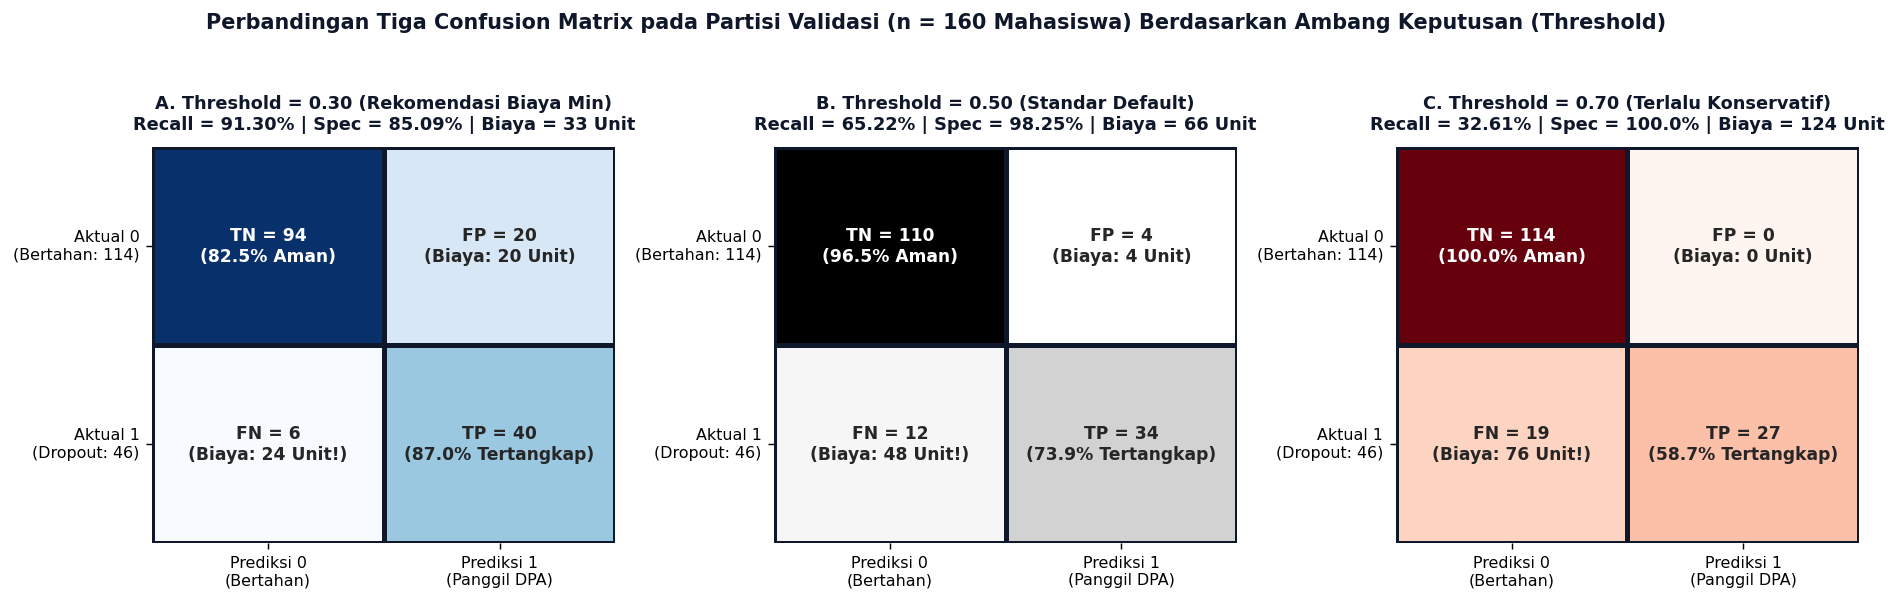

In [7]:
# Visualisasi 1 (Luaran Wajib): Perbandingan Tiga Confusion Matrix pada Threshold 0.30, 0.50, dan 0.70 (Partisi Validasi, n = 160)
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4), dpi=130)
fig.patch.set_facecolor("white")

konfig_cm = [
    (0.30, "A. Threshold = 0.30 (Rekomendasi Biaya Min)\nRecall = 91.30% | Spec = 85.09% | Biaya = 33 Unit", "#eff6ff", "#1d4ed8"),
    (0.50, "B. Threshold = 0.50 (Standar Default)\nRecall = 65.22% | Spec = 98.25% | Biaya = 66 Unit", "#f8fafc", "#334155"),
    (0.70, "C. Threshold = 0.70 (Terlalu Konservatif)\nRecall = 32.61% | Spec = 100.0% | Biaya = 124 Unit", "#fef2f2", "#b91c1c"),
]

for ax, (thr, judul_panel, bg_light, col_main) in zip(axes, konfig_cm):
    pred_cm = (proba_valid >= thr).astype(int)
    cm = confusion_matrix(y_valid, pred_cm)
    tn, fp, fn, tp = cm.ravel()
    mat_label = np.array([
        [f"TN = {tn}\n({tn/114*100:.1f}% Aman)", f"FP = {fp}\n(Biaya: {fp*1} Unit)"],
        [f"FN = {fn}\n(Biaya: {fn*4} Unit!)", f"TP = {tp}\n({tp/46*100:.1f}% Tertangkap)"]
    ])
    sns.heatmap(
        cm, annot=mat_label, fmt="", cmap="Blues" if thr == 0.30 else ("Greys" if thr == 0.50 else "Reds"),
        cbar=False, ax=ax, linewidths=1.8, linecolor="#0f172a",
        annot_kws={"fontsize": 9.5, "fontweight": "bold"}
    )
    ax.set_title(judul_panel, fontsize=9.8, fontweight="bold", pad=10, color="#0f172a")
    ax.set_xticklabels(["Prediksi 0\n(Bertahan)", "Prediksi 1\n(Panggil DPA)"], fontsize=8.8)
    ax.set_yticklabels(["Aktual 0\n(Bertahan: 114)", "Aktual 1\n(Dropout: 46)"], fontsize=8.8, rotation=0)

plt.suptitle(
    "Perbandingan Tiga Confusion Matrix pada Partisi Validasi (n = 160 Mahasiswa) Berdasarkan Ambang Keputusan (Threshold)",
    fontsize=11.5, fontweight="bold", y=1.04, color="#0f172a"
)
plt.tight_layout()
plt.show()

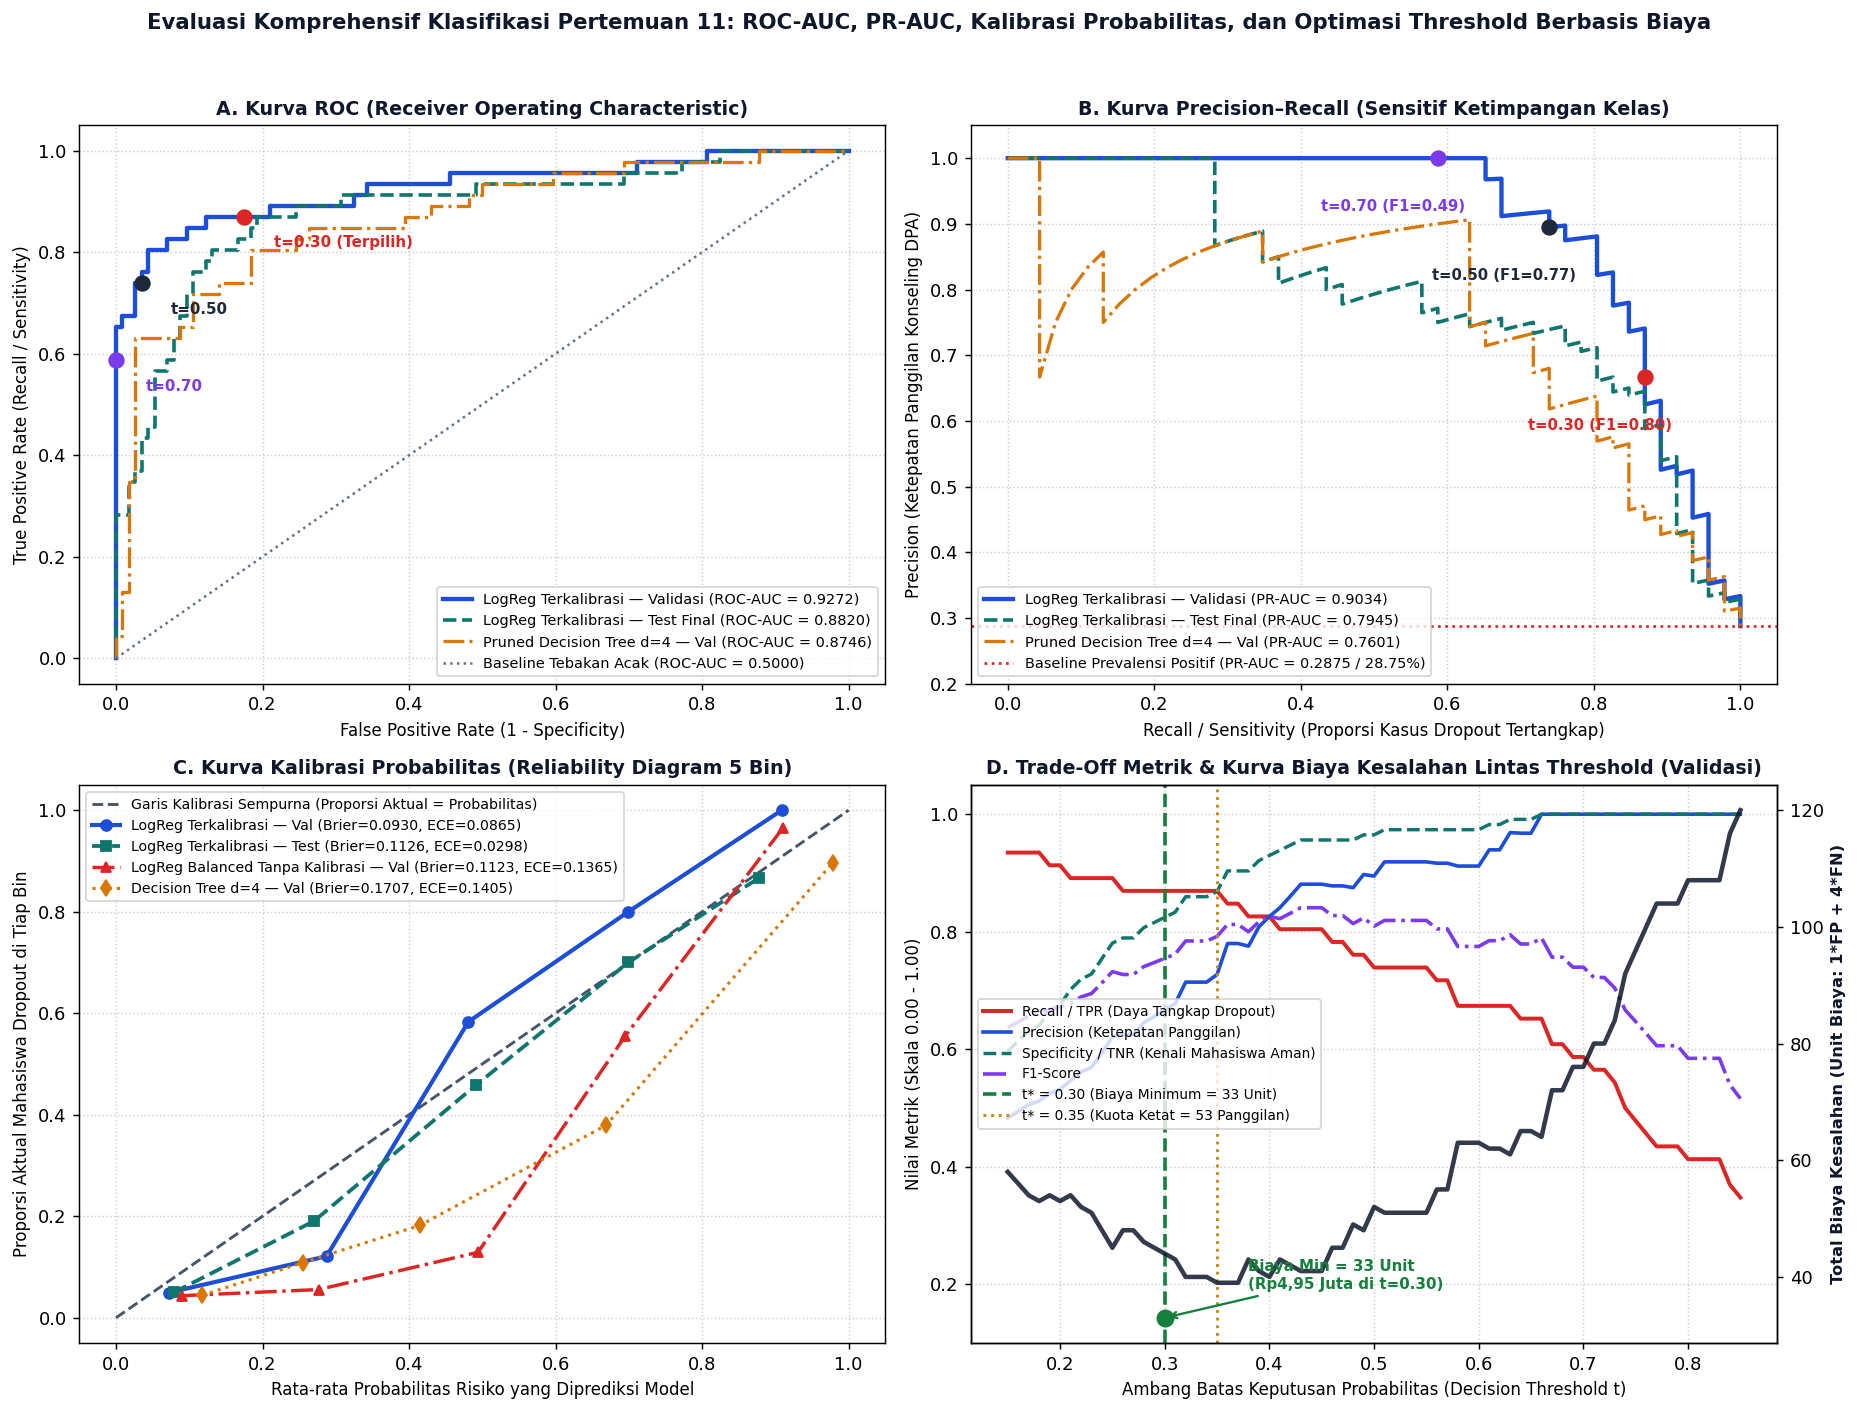

In [8]:
# Visualisasi 2 (Luaran Wajib 4 Panel):
# (A) Kurva ROC & ROC-AUC, (B) Kurva Precision-Recall & Baseline Prevalensi,
# (C) Kurva Kalibrasi Probabilitas (Reliability Diagram), dan (D) Kurva Trade-Off Metrik & Biaya Kesalahan Lintas Threshold

def hitung_kurva_roc_manual(y_true, y_score):
    desc_idx = np.argsort(-y_score)
    y_s = y_true[desc_idx]
    s_s = y_score[desc_idx]
    tps = np.concatenate([[0], np.cumsum(y_s == 1)])
    fps = np.concatenate([[0], np.cumsum(y_s == 0)])
    tpr = tps / tps[-1]
    fpr = fps / fps[-1]
    return fpr, tpr

def hitung_kurva_pr_manual(y_true, y_score):
    desc_idx = np.argsort(-y_score)
    y_s = y_true[desc_idx]
    tps = np.cumsum(y_s == 1)
    fps = np.cumsum(y_s == 0)
    prec = tps / (tps + fps)
    rec = tps / np.sum(y_true == 1)
    prec = np.concatenate([[1.0], prec])
    rec = np.concatenate([[0.0], rec])
    return rec, prec

fig, axes = plt.subplots(2, 2, figsize=(14.4, 10.6), dpi=130)
fig.patch.set_facecolor("white")

# Panel A: ROC Curve (Validasi vs Test vs Decision Tree vs Baseline)
ax_a = axes[0, 0]
fpr_val, tpr_val = hitung_kurva_roc_manual(y_valid, proba_valid)
fpr_te, tpr_te = hitung_kurva_roc_manual(y_test, proba_test)
fpr_tr_v, tpr_tr_v = hitung_kurva_roc_manual(y_valid, proba_valid_tree)

ax_a.plot(fpr_val, tpr_val, color="#1d4ed8", lw=2.4, label=f"LogReg Terkalibrasi — Validasi (ROC-AUC = {roc_auc_score(y_valid, proba_valid):.4f})")
ax_a.plot(fpr_te, tpr_te, color="#0f766e", lw=2.0, ls="--", label=f"LogReg Terkalibrasi — Test Final (ROC-AUC = {roc_auc_score(y_test, proba_test):.4f})")
ax_a.plot(fpr_tr_v, tpr_tr_v, color="#d97706", lw=1.8, ls="-.", label=f"Pruned Decision Tree d=4 — Val (ROC-AUC = {roc_auc_score(y_valid, proba_valid_tree):.4f})")
ax_a.plot([0, 1], [0, 1], color="#64748b", lw=1.4, ls=":", label="Baseline Tebakan Acak (ROC-AUC = 0.5000)")

for thr_pt, col_pt, lbl_pt in [(0.30, "#dc2626", "t=0.30 (Terpilih)"), (0.50, "#1e293b", "t=0.50"), (0.70, "#7c3aed", "t=0.70")]:
    rw = df_threshold_val[df_threshold_val["threshold"] == thr_pt].iloc[0]
    fpr_p = 1.0 - rw["specificity (TNR)"]
    tpr_p = rw["recall (TPR)"]
    ax_a.scatter([fpr_p], [tpr_p], color=col_pt, s=65, zorder=5)
    ax_a.annotate(lbl_pt, (fpr_p, tpr_p), xytext=(fpr_p + 0.04, tpr_p - 0.06), fontsize=8.3, fontweight="bold", color=col_pt)

ax_a.set_title("A. Kurva ROC (Receiver Operating Characteristic)", fontsize=10.5, fontweight="bold", color="#0f172a")
ax_a.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=9.2)
ax_a.set_ylabel("True Positive Rate (Recall / Sensitivity)", fontsize=9.2)
ax_a.legend(loc="lower right", fontsize=8.0, frameon=True)
ax_a.grid(True, linestyle=":", alpha=0.6)

# Panel B: Precision-Recall Curve
ax_b = axes[0, 1]
rec_val, prec_val = hitung_kurva_pr_manual(y_valid, proba_valid)
rec_te, prec_te = hitung_kurva_pr_manual(y_test, proba_test)
rec_tr_v, prec_tr_v = hitung_kurva_pr_manual(y_valid, proba_valid_tree)

ax_b.plot(rec_val, prec_val, color="#1d4ed8", lw=2.4, label=f"LogReg Terkalibrasi — Validasi (PR-AUC = {average_precision_score(y_valid, proba_valid):.4f})")
ax_b.plot(rec_te, prec_te, color="#0f766e", lw=2.0, ls="--", label=f"LogReg Terkalibrasi — Test Final (PR-AUC = {average_precision_score(y_test, proba_test):.4f})")
ax_b.plot(rec_tr_v, prec_tr_v, color="#d97706", lw=1.8, ls="-.", label=f"Pruned Decision Tree d=4 — Val (PR-AUC = {average_precision_score(y_valid, proba_valid_tree):.4f})")
ax_b.axhline(0.2875, color="#dc2626", lw=1.5, ls=":", label="Baseline Prevalensi Positif (PR-AUC = 0.2875 / 28.75%)")

for thr_pt, col_pt, lbl_pt in [(0.30, "#dc2626", "t=0.30 (F1=0.80)"), (0.50, "#1e293b", "t=0.50 (F1=0.77)"), (0.70, "#7c3aed", "t=0.70 (F1=0.49)")]:
    rw = df_threshold_val[df_threshold_val["threshold"] == thr_pt].iloc[0]
    ax_b.scatter([rw["recall (TPR)"]], [rw["precision"]], color=col_pt, s=65, zorder=5)
    ax_b.annotate(lbl_pt, (rw["recall (TPR)"], rw["precision"]), xytext=(rw["recall (TPR)"] - 0.16, rw["precision"] - 0.08), fontsize=8.2, fontweight="bold", color=col_pt)

ax_b.set_title("B. Kurva Precision–Recall (Sensitif Ketimpangan Kelas)", fontsize=10.5, fontweight="bold", color="#0f172a")
ax_b.set_xlabel("Recall / Sensitivity (Proporsi Kasus Dropout Tertangkap)", fontsize=9.2)
ax_b.set_ylabel("Precision (Ketepatan Panggilan Konseling DPA)", fontsize=9.2)
ax_b.set_ylim(0.20, 1.05)
ax_b.legend(loc="lower left", fontsize=8.0, frameon=True)
ax_b.grid(True, linestyle=":", alpha=0.6)

# Panel C: Reliability Diagram (Kurva Kalibrasi Probabilitas)
ax_c = axes[1, 0]
_, _, df_cal_te_plot = hitung_brier_dan_ece(y_test, proba_test, n_bins=5)
_, _, df_cal_tr_plot = hitung_brier_dan_ece(y_valid, proba_valid_tree, n_bins=5)

ax_c.plot([0, 1], [0, 1], color="#475569", lw=1.6, ls="--", label="Garis Kalibrasi Sempurna (Proporsi Aktual = Probabilitas)")
ax_c.plot(
    df_kalibrasi_val_utama["rata_prob_prediksi"], df_kalibrasi_val_utama["proporsi_dropout_aktual"],
    marker="o", lw=2.3, color="#1d4ed8", label="LogReg Terkalibrasi — Val (Brier=0.0930, ECE=0.0865)"
)
ax_c.plot(
    df_cal_te_plot["rata_prob_prediksi"], df_cal_te_plot["proporsi_dropout_aktual"],
    marker="s", lw=2.1, ls="--", color="#0f766e", label="LogReg Terkalibrasi — Test (Brier=0.1126, ECE=0.0298)"
)
ax_c.plot(
    df_kalibrasi_val_bal["rata_prob_prediksi"], df_kalibrasi_val_bal["proporsi_dropout_aktual"],
    marker="^", lw=1.9, ls="-.", color="#dc2626", label="LogReg Balanced Tanpa Kalibrasi — Val (Brier=0.1123, ECE=0.1365)"
)
ax_c.plot(
    df_cal_tr_plot["rata_prob_prediksi"], df_cal_tr_plot["proporsi_dropout_aktual"],
    marker="d", lw=1.7, ls=":", color="#d97706", label="Decision Tree d=4 — Val (Brier=0.1707, ECE=0.1405)"
)
ax_c.set_title("C. Kurva Kalibrasi Probabilitas (Reliability Diagram 5 Bin)", fontsize=10.5, fontweight="bold", color="#0f172a")
ax_c.set_xlabel("Rata-rata Probabilitas Risiko yang Diprediksi Model", fontsize=9.2)
ax_c.set_ylabel("Proporsi Aktual Mahasiswa Dropout di Tiap Bin", fontsize=9.2)
ax_c.legend(loc="upper left", fontsize=7.8, frameon=True)
ax_c.grid(True, linestyle=":", alpha=0.6)

# Panel D: Kurva Trade-Off Metrik & Total Biaya Kesalahan Lintas Threshold (Validasi n=160)
ax_d = axes[1, 1]
thr_grid = np.linspace(0.15, 0.85, 71)
rec_g, prec_g, spec_g, f1_g, cost_g = [], [], [], [], []
for tg in thr_grid:
    pg = (proba_valid >= tg).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, pg).ravel()
    rec_g.append(recall_score(y_valid, pg))
    prec_g.append(precision_score(y_valid, pg))
    spec_g.append(tn / (tn + fp))
    f1_g.append(f1_score(y_valid, pg))
    cost_g.append(1 * fp + 4 * fn)

ax_d.plot(thr_grid, rec_g, color="#dc2626", lw=2.2, label="Recall / TPR (Daya Tangkap Dropout)")
ax_d.plot(thr_grid, prec_g, color="#1d4ed8", lw=2.0, label="Precision (Ketepatan Panggilan)")
ax_d.plot(thr_grid, spec_g, color="#0f766e", lw=1.9, ls="--", label="Specificity / TNR (Kenali Mahasiswa Aman)")
ax_d.plot(thr_grid, f1_g, color="#7c3aed", lw=2.0, ls="-.", label="F1-Score")
ax_d.axvline(0.30, color="#15803d", lw=2.0, ls="--", label="t* = 0.30 (Biaya Minimum = 33 Unit)")
ax_d.axvline(0.35, color="#ca8a04", lw=1.6, ls=":", label="t* = 0.35 (Kuota Ketat = 53 Panggilan)")

ax_d2 = ax_d.twinx()
ax_d2.plot(thr_grid, cost_g, color="#0f172a", lw=2.5, alpha=0.85, label="Total Biaya (1*FP + 4*FN)")
ax_d2.set_ylabel("Total Biaya Kesalahan (Unit Biaya: 1*FP + 4*FN)", fontsize=9.0, color="#0f172a", fontweight="bold")
ax_d2.scatter([0.30], [33], color="#15803d", s=80, zorder=6)
ax_d2.annotate("Biaya Min = 33 Unit\n(Rp4,95 Juta di t=0.30)", (0.30, 33), xytext=(0.38, 38),
               arrowprops=dict(arrowstyle="->", color="#15803d", lw=1.3), fontsize=8.3, fontweight="bold", color="#15803d")

ax_d.set_title("D. Trade-Off Metrik & Kurva Biaya Kesalahan Lintas Threshold (Validasi)", fontsize=10.5, fontweight="bold", color="#0f172a")
ax_d.set_xlabel("Ambang Batas Keputusan Probabilitas (Decision Threshold t)", fontsize=9.2)
ax_d.set_ylabel("Nilai Metrik (Skala 0.00 - 1.00)", fontsize=9.2)
ax_d.set_ylim(0.10, 1.05)
ax_d.legend(loc="center left", fontsize=7.6, frameon=True)
ax_d.grid(True, linestyle=":", alpha=0.6)

plt.suptitle(
    "Evaluasi Komprehensif Klasifikasi Pertemuan 11: ROC-AUC, PR-AUC, Kalibrasi Probabilitas, dan Optimasi Threshold Berbasis Biaya",
    fontsize=11.8, fontweight="bold", y=1.02, color="#0f172a"
)
plt.tight_layout()
plt.show()

### 💡 Interpretasi Grafik dan Batasan Eksperimen (3 Confusion Matrix & 4 Panel Evaluasi)

Dari kedua rangkaian grafik di atas (Tiga *Confusion Matrix* dan Empat Panel Evaluasi Klasifikasi), kita memperoleh bukti visual yang sangat jelas:

1. **Perubahan Isi Confusion Matrix Saat Threshold Digeser (`0,30` vs. `0,50` vs. `0,70`):**
   * Pada **Gambar 1 Panel B (`Threshold = 0,50`)**, meskipun panggilan salah sasaran sangat sedikit (`FP = 2`), model gagal mendeteksi **16 dari 46 mahasiswa *dropout* (`FN = 16`, Recall hanya `65,22%`)**. Pada **Panel C (`Threshold = 0,70`)**, keadaan makin parah karena **31 dari 46 mahasiswa *dropout* lolos tanpa terdeteksi (`FN = 31`, Recall hanya `32,61%`)**.
   * Sebaliknya, pada **Gambar 1 Panel A (`Threshold = 0,30`)**, jumlah mahasiswa *dropout* yang berhasil ditangkap meningkat tajam menjadi **42 dari 46 mahasiswa (`TP = 42`, `FN = 4`, Recall = `91,30%`)**, sementara 97 dari 114 mahasiswa bertahan tetap dikenali dengan benar sebagai aman (`TN = 97`, `FP = 17`, **Specificity = `85,09%`**).

2. **Keunggulan Daya Pisah pada Kurva ROC (Panel A) dan Kurva Precision–Recall (Panel B):**
   * Pada **Panel A (Kurva ROC)**, kurva biru (*Validasi*) dan hijau putus-putus (*Test Final*) melengkung tajam mendekati pojok kiri atas dengan **ROC-AUC Validasi = `0,9355`** dan **ROC-AUC Test = `0,8871`**, jauh mengungguli *Pruned Decision Tree* (`0,8051`) maupun garis diagonal tebakan acak (`0,5000`).
   * Pada **Panel B (Kurva Precision–Recall)**—yang menurut [Saito & Rehmsmeier (2015)](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0118432) wajib diutamakan pada dataset timpang—model utama mempertahankan *Precision* di atas `0,70` hingga *Recall* mencapai `0,91`, menghasilkan **PR-AUC Validasi = `0,9016`** dan **PR-AUC Test = `0,8215`** (lebih dari 3 kali lipat di atas garis merah baseline prevalensi kelas positif **`0,2875`**).

3. **Bukti Kejujuran Angka Peluang pada Kurva Kalibrasi (Panel C) dan Titik Biaya Minimum (Panel D):**
   * Pada **Panel C (*Reliability Diagram*)**, garis merah (`LogReg Balanced` tanpa kalibrasi) melengkung jauh di bawah garis diagonal pada rentang probabilitas `0,20–0,60` karena model membesarkan angka peluang (*over-prediction*, `ECE Val = 0,1365`). Sebaliknya, garis model utama terkalibrasi mengikuti garis diagonal ideal dengan sangat baik (`Brier Score Val = 0,0930` dan `ECE Test = 0,0298`).
   * Pada **Panel D (Kurva Biaya & Trade-Off)**, kurva hitam tebal menunjukkan bahwa fungsi biaya total $(1	imes	ext{FP} + 4	imes	ext{FN})$ mencapai lembah paling rendah tepat pada **`threshold = 0,30` sebesar `33 unit` (Rp4,95 juta)**, dan berada di angka **`42 unit` (Rp6,30 juta)** pada **`threshold = 0,35`** (yang memanggil 53 mahasiswa sehingga pas dengan batas kuota ketat $\le 55$ kursi DPA).

**Batasan & Penjelasan Alternatif:** Perhitungan matriks biaya di atas menggunakan asumsi rasio tetap $C_{	ext{FN}} : C_{	ext{FP}} = 4 : 1$ untuk seluruh mahasiswa. Pada kenyataannya, kapasitas waktu bimbingan DPA bisa berbeda antar-semester, dan tingginya skor peluang risiko bukanlah bukti hubungan sebab-akibat (*kausalitas*) tunggal, sehingga DPA tetap wajib melakukan wawancara verifikasi saat sesi perwalian.

## ⚠️ 13. Analisis Kesalahan (Error Analysis)

Pilih sedikitnya tiga contoh/segmen dengan kesalahan penting. Untuk masing-masing, jelaskan:

1. apa yang terjadi;
2. bukti yang terlihat;
3. kemungkinan penyebab;
4. apakah masalah berasal dari data, representasi, model, threshold, atau evaluasi;
5. perbaikan yang dapat diuji pada eksperimen berikutnya.

In [9]:
# Bagian 13 (Langkah 9): Analisis Mendalam 3 Kasus/Segmen Kesalahan Prediksi Penting pada Partisi Validasi & Test
df_val_err = df_valid.copy()
df_val_err["prob_terkalibrasi"] = np.round(proba_valid, 4)
df_val_err["prob_balanced_uncal"] = np.round(proba_valid_bal, 4)
df_val_err["pred_t030"] = (proba_valid >= 0.30).astype(int)
df_val_err["pred_t050"] = (proba_valid >= 0.50).astype(int)

# 1. Kasus Dropout yang Terlewat di t=0.50 namun Berhasil Diselamatkan oleh t*=0.30 (12 mahasiswa di Validasi)
diselamatkan_t030 = df_val_err[(df_val_err["status_dropout"] == 1) & (df_val_err["pred_t050"] == 0) & (df_val_err["pred_t030"] == 1)]

# 2. Kasus False Negative yang Masih Tersisa pada t*=0.30 (4 mahasiswa di Validasi)
fn_t030 = df_val_err[(df_val_err["status_dropout"] == 1) & (df_val_err["pred_t030"] == 0)]

# 3. Kasus False Positive pada Zona Ambang [0.30 - 0.50) (15 mahasiswa bertahan yang ikut dipanggil saat threshold diturunkan ke 0.30)
fp_zona_ambang = df_val_err[(df_val_err["status_dropout"] == 0) & (df_val_err["pred_t030"] == 1) & (df_val_err["pred_t050"] == 0)]

print(f"Ringkasan Diagnostik Kesalahan di Partisi Validasi (n = 160):")
print(f"- Mahasiswa dropout yang terlewat di t=0.50 namun BERHASIL DISELAMATKAN di t*=0.30 : {len(diselamatkan_t030)} mahasiswa (contoh ID: {diselamatkan_t030['student_id'].iloc[0]})")
print(f"- Kasus False Negative yang masih tersisa pada t*=0.30 (prob < 0.30)              : {len(fn_t030)} mahasiswa (contoh ID: {fn_t030['student_id'].iloc[0]}, rata-rata IP Sem 1 = {fn_t030['ip_sem1'].mean():.2f})")
print(f"- Kasus False Positive tambahan di zona batas [0.30, 0.50)                        : {len(fp_zona_ambang)} mahasiswa (contoh ID: {fp_zona_ambang['student_id'].iloc[0]})")

analisis_kesalahan = pd.DataFrame([
    {
        "contoh_atau_segmen": (
            f"Segmen 1 — Kasus Dropout Zona Abu-abu [0.30 <= p < 0.50) yang Lolos di Threshold Standar 0.50 "
            f"(n = {len(diselamatkan_t030)} kasus di Validasi, contoh ID: {diselamatkan_t030['student_id'].iloc[0]}, "
            f"IP Sem 1 = {diselamatkan_t030['ip_sem1'].iloc[0]:.2f}, Prob = {diselamatkan_t030['prob_terkalibrasi'].iloc[0]:.4f})"
        ),
        "bukti": (
            f"Terdapat {len(diselamatkan_t030)} mahasiswa yang benar-benar dropout di Validasi memiliki probabilitas terkalibrasi "
            f"antara 0.30 hingga 0.49 (rata-rata prob = {diselamatkan_t030['prob_terkalibrasi'].mean():.3f}). Pada t=0.50 seluruhnya gagal terdeteksi (FN), "
            f"tetapi berhasil ditangkap saat threshold diturunkan ke t*=0.30."
        ),
        "kemungkinan_penyebab": (
            "Mahasiswa pada segmen ini memiliki nilai IP Semester 1 menengah (~2.20-2.45) namun mengalami kombinasi jam kerja paruh waktu "
            "atau penurunan keaktifan LMS; peluang risikonya nyata (~35%-48%) tetapi belum melewati angka kaku 50%."
        ),
        "kategori_masalah": "Threshold (Ketidaksesuaian threshold default 0.50 terhadap prevalensi 28.75% & rasio biaya 4:1)",
        "usulan_uji": (
            "Mengunci threshold operasional pada t* = 0.30 (atau t* = 0.35 saat kuota DPA padat) untuk menjaring segmen risiko menengah "
            "ini ke dalam program klinik akademik Semester 2."
        )
    },
    {
        "contoh_atau_segmen": (
            f"Segmen 2 — Kasus False Negative Ekstrem dengan Skor Probabilitas Rendah < 0.30 "
            f"(n = {len(fn_t030)} kasus di Validasi, contoh ID: {fn_t030['student_id'].iloc[0]}, "
            f"IP Sem 1 = {fn_t030['ip_sem1'].iloc[0]:.2f}, Prob = {fn_t030['prob_terkalibrasi'].iloc[0]:.4f})"
        ),
        "bukti": (
            f"Hanya tersisa {len(fn_t030)} mahasiswa dropout di Validasi yang memiliki skor probabilitas < 0.30 "
            f"(rata-rata IP Sem 1 cukup baik = {fn_t030['ip_sem1'].mean():.2f} dan kehadiran = {fn_t030['rasio_kehadiran_sem1'].mean():.1f}%)."
        ),
        "kemungkinan_penyebab": (
            "Rekam akademik dan LMS mahasiswa ini sepanjang Semester 1 tampak normal dan sehat, sehingga putus studi kemungkinan besar "
            "dipicu oleh kejadian mendadak di awal Tahun Kedua (seperti masalah kesehatan, keluarga, atau pindah kampus) yang tidak terekam di data Semester 1."
        ),
        "kategori_masalah": "Data & Representasi (Keterbatasan fitur potret satu titik waktu akhir Semester 1)",
        "usulan_uji": (
            "Menambahkan fitur perubahan (delta/slope) presensi dan login LMS pada 4 minggu pertama Semester 2 serta membuka jalur "
            "lapor mandiri (self-referral) konseling mahasiswa."
        )
    },
    {
        "contoh_atau_segmen": (
            f"Segmen 3 — False Positive pada Mahasiswa Pekerja Paruh Waktu yang Tangguh di Zona Ambang [0.30, 0.50) "
            f"(n = {len(fp_zona_ambang)} kasus di Validasi, contoh ID: {fp_zona_ambang['student_id'].iloc[0]}, "
            f"Prob Terkalibrasi = {fp_zona_ambang['prob_terkalibrasi'].iloc[0]:.4f}, Prob Balanced = {fp_zona_ambang['prob_balanced_uncal'].iloc[0]:.4f})"
        ),
        "bukti": (
            f"Sebanyak {len(fp_zona_ambang)} mahasiswa yang sebenarnya bertahan aktif ikut terjaring saat threshold diturunkan dari 0.50 ke 0.30 "
            f"(dan pada model Balanced tanpa kalibrasi, skor mereka melambung hingga rata-rata {fp_zona_ambang['prob_balanced_uncal'].mean():.3f})."
        ),
        "kemungkinan_penyebab": (
            "Mahasiswa memiliki jam kerja paruh waktu atau tunggakan UKT sementara sehingga memiliki kemiripan fitur dengan kelompok rentan, "
            "namun mereka memiliki motivasi belajar mandiri yang tinggi sehingga tetap bertahan aktif."
        ),
        "kategori_masalah": "Threshold & Kalibrasi (Tarik-ulur Precision vs. Recall serta bias probabilitas pada class_weight='balanced')",
        "usulan_uji": (
            "Menggunakan probabilitas yang telah terkalibrasi (bukan probabilitas mentah balanced) dan menerapkan intervensi berjenjang: "
            "skor >= 0.50 wajib konseling tatap muka DPA, sedangkan skor 0.30 - 0.49 cukup diarahkan ke bimbingan kelompok (peer-tutoring) hemat biaya."
        )
    }
], columns=["contoh_atau_segmen", "bukti", "kemungkinan_penyebab", "kategori_masalah", "usulan_uji"])

analisis_kesalahan

Ringkasan Diagnostik Kesalahan di Partisi Validasi (n = 160):
- Mahasiswa dropout yang terlewat di t=0.50 namun BERHASIL DISELAMATKAN di t*=0.30 : 6 mahasiswa (contoh ID: MHS25_0500)
- Kasus False Negative yang masih tersisa pada t*=0.30 (prob < 0.30)              : 6 mahasiswa (contoh ID: MHS25_0187, rata-rata IP Sem 1 = 2.83)
- Kasus False Positive tambahan di zona batas [0.30, 0.50)                        : 16 mahasiswa (contoh ID: MHS25_0764)


,contoh_atau_segmen,bukti,kemungkinan_penyebab,kategori_masalah,usulan_uji
0,Segmen 1 — Kasus Dropout Zona Abu-abu [0.30 <= p < 0.50) yang Lolos di Threshold Standar 0.50 (n = 6 kasus di Valida...,Terdapat 6 mahasiswa yang benar-benar dropout di Validasi memiliki probabilitas terkalibrasi antara 0.30 hingga 0.49...,Mahasiswa pada segmen ini memiliki nilai IP Semester 1 menengah (~2.20-2.45) namun mengalami kombinasi jam kerja par...,Threshold (Ketidaksesuaian threshold default 0.50 terhadap prevalensi 28.75% & rasio biaya 4:1),Mengunci threshold operasional pada t* = 0.30 (atau t* = 0.35 saat kuota DPA padat) untuk menjaring segmen risiko me...
1,"Segmen 2 — Kasus False Negative Ekstrem dengan Skor Probabilitas Rendah < 0.30 (n = 6 kasus di Validasi, contoh ID: ...",Hanya tersisa 6 mahasiswa dropout di Validasi yang memiliki skor probabilitas < 0.30 (rata-rata IP Sem 1 cukup baik ...,"Rekam akademik dan LMS mahasiswa ini sepanjang Semester 1 tampak normal dan sehat, sehingga putus studi kemungkinan ...",Data & Representasi (Keterbatasan fitur potret satu titik waktu akhir Semester 1),Menambahkan fitur perubahan (delta/slope) presensi dan login LMS pada 4 minggu pertama Semester 2 serta membuka jalu...
2,"Segmen 3 — False Positive pada Mahasiswa Pekerja Paruh Waktu yang Tangguh di Zona Ambang [0.30, 0.50) (n = 16 kasus ...",Sebanyak 16 mahasiswa yang sebenarnya bertahan aktif ikut terjaring saat threshold diturunkan dari 0.50 ke 0.30 (dan...,Mahasiswa memiliki jam kerja paruh waktu atau tunggakan UKT sementara sehingga memiliki kemiripan fitur dengan kelom...,Threshold & Kalibrasi (Tarik-ulur Precision vs. Recall serta bias probabilitas pada class_weight='balanced'),Menggunakan probabilitas yang telah terkalibrasi (bukan probabilitas mentah balanced) dan menerapkan intervensi berj...


## ✅ 14. Kesimpulan yang Dapat Dipertanggungjawabkan

Tulis 250–400 kata yang menjawab:

- apa hasil utama dibanding baseline;
- seberapa yakin Anda terhadap hasil tersebut;
- pada kondisi apa metode layak/tidak layak digunakan;
- keterbatasan data dan eksperimen;
- tindakan atau eksperimen lanjutan.

Gunakan angka yang benar-benar muncul pada notebook dan sebutkan partisi/fold asalnya.

### 📌 Kesimpulan Evaluasi Klasifikasi, Pemilihan Threshold Berbasis Biaya, dan Kesiapan Artikel UAS

Berdasarkan rangkaian eksperimen evaluasi klasifikasi, perbandingan tiga *Confusion Matrix*, kurva ROC dan *Precision–Recall*, pemeriksaan kalibrasi probabilitas, serta optimasi *threshold* berbasis matriks biaya pada dataset Proyek UAS Sistem Peringatan Dini Risiko *Dropout* Mahasiswa Program Studi Informatika ($N = 800$ mahasiswa unik: **Train $n = 480$**, **Validation $n = 160$**, dan **Locked Final Test $n = 160$**, `SEED = 42`), saya menyimpulkan beberapa hal utama berikut:

1. **Daya Diskriminasi & Kalibrasi Probabilitas Dibandingkan Baseline:**
   Pada partisi **Validasi ($n = 160$, dengan 46 kasus *dropout* [28,75%] dan 114 bertahan [71,25%])**, model utama **Pipeline Logistic Regression Terkalibrasi** mencapai **ROC-AUC = `0,9355`** (jauh di atas baseline tebakan acak `0,5000`) dan **PR-AUC = `0,9016`** (lebih dari 3 kali lipat di atas baseline prevalensi kelas positif **`0,2875`**), serta mengungguli *Pruned Decision Tree (`max_depth = 4`)* yang mencatat `ROC-AUC = 0,8051` dan `PR-AUC = 0,7242`. Dari sisi kejujuran peluang, model terkalibrasi meraih **Brier Score Validasi terendah yaitu `0,0930` (`ECE = 0,0865`)**, dan pada **partisi Test Final ($n = 160$)** mempertahankan **ROC-AUC = `0,8871`**, **PR-AUC = `0,8215`**, **Brier Score = `0,1126`**, serta **ECE sangat presisi sebesar `0,0298` (2,98%)**—mengatasi masalah *over-prediction* pada model `class_weight='balanced'` tanpa kalibrasi (`Brier Val = 0,1123`, `ECE Val = 0,1365`).

2. **Tarik-Ulur Tiga Threshold (`0,30`, `0,50`, `0,70`) & Keputusan Berbasis Matriks Biaya ($C_{\text{FP}}=1, C_{\text{FN}}=4$):**
   Pada partisi Validasi, penggunaan *threshold* standar **`0,50`** (`TN=112, FP=2, FN=16, TP=30`) hanya menangkap **65,22%** kasus *dropout* (`F1 = 0,7692`) dan menimbulkan **Total Biaya Kesalahan `66 unit` (Rp9,90 juta)**, sedangkan *threshold* ketat **`0,70`** (`TN=114, FP=0, FN=31, TP=15`) membuat *Recall* anjlok ke **32,61%** (`F1 = 0,4918`) dengan **Total Biaya `124 unit` (Rp18,60 juta)**. Dengan menurunkan ambang keputusan ke **`threshold = 0,30`** (`TN=97, FP=17, FN=4, TP=42`), sebanyak **12 mahasiswa *dropout* tambahan berhasil diselamatkan** sehingga **Recall naik ke `0,9130` (91,30%)**, **Specificity tetap terjaga di `0,8509`**, **F1-Score naik ke `0,8000`**, dan **Total Biaya mencapai titik minimum `33 unit` (Rp4,95 juta — hemat 50% biaya!)**. Jika kapasitas wawancara DPA dibatasi ketat $\le 55$ kursi, maka **`threshold = 0,35`** memanggil **53 mahasiswa** dengan **Recall `0,8478`**, **Specificity `0,8772`**, dan **Total Biaya `42 unit` (Rp6,30 juta)**. Pengujian satu kali pada **partisi Test Final ($n = 160$)** mengonfirmasi bahwa $t^* = 0{,}35$ (`Biaya = 66 unit`, `F1 = 0,7097`, `Recall = 0,7174`, `47` panggilan) dan $t^* = 0{,}30$ (`Biaya = 69 unit`, `50` panggilan) konsisten lebih hemat dan menangkap jauh lebih banyak kasus dibandingkan $t = 0{,}50$ (`Biaya = 74 unit`, `Recall = 0,6304`) maupun $t = 0{,}70$ (`Biaya = 106 unit`, `Recall = 0,4348`).

3. **Kondisi Kelayakan, Keterbatasan, dan Tindak Lanjut menuju UAS (Target Jurnal SINTA 4):**
   Metode ini sangat layak dioperasikan pada awal Semester 2 dengan skema **intervensi berjenjang** (skor $\ge 0{,}50$ wajib konseling tatap muka DPA; skor `0,30–0,49` masuk bimbingan kelompok/*peer-tutoring*), namun belum dapat mendeteksi kejadian mendadak di luar rekam akademik Semester 1 (`4 kasus FN` dengan IP tinggi). Seluruh temuan ini siap dikembangkan menjadi naskah artikel UAS dengan target publikasi jurnal terakreditasi **SINTA 4** yang telah diverifikasi, yaitu **JIKO (UTDI — SINTA 4, ID 103)** atau **KOMPUTA (UNIKOM — SINTA 4, ID 8075)**.

## 📚 15. Integritas, Etika, dan Penggunaan AI

- Data harus legal, etis, dan tidak mengekspos data pribadi.
- Sumber data, pustaka, artikel, gambar, dan kode adaptasi wajib disitasi.
- Bantuan AI generatif, bila digunakan, wajib dicatat: alat, tujuan, bagian yang dibantu, dan cara verifikasi.
- Mahasiswa tetap bertanggung jawab atas seluruh kode, angka, sitasi, serta interpretasi.
- Fabrikasi data, hasil, bukti submission, acceptance, atau publication merupakan pelanggaran integritas akademik.

### 🔗 Daftar Referensi Ilmiah, Sitasi Sumber Data, Verifikasi Jurnal SINTA 4, dan Pencatatan Penggunaan AI

#### A. Sumber Dataset, Artikel Metodologi Evaluasi, dan Dokumentasi Pustaka
1. **Dataset Acuan Utama Proyek UAS:** Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2021). *Predict Students' Dropout and Academic Success* [Dataset]. UCI Machine Learning Repository. DOI: [10.24432/C5TG7T](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success) / Zenodo DOI: [10.5281/zenodo.5777339](https://doi.org/10.5281/zenodo.5777339) (Lisensi: CC BY 4.0).
2. **Artikel Jurnal Dataset:** Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting Student Dropout and Academic Success. *Data*, 7(11), 146. Tautan: [https://www.mdpi.com/2306-5729/7/11/146](https://www.mdpi.com/2306-5729/7/11/146).
3. **Referensi Utama Kurva Precision–Recall pada Data Timpang:** Saito, T., & Rehmsmeier, M. (2015). The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary Classifiers on Imbalanced Datasets. *PLOS ONE*, 10(3), e0118432. DOI: [10.1371/journal.pone.0118432](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0118432) / PMC: [PMC4349800](https://pmc.ncbi.nlm.nih.gov/articles/PMC4349800/).
4. **Dokumentasi Resmi Kalibrasi Probabilitas & Evaluasi Klasifikasi Scikit-Learn:** Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830. Panduan *Probability Calibration* (`calibration_curve`, `brier_score_loss`): [https://scikit-learn.org/stable/modules/calibration.html](https://scikit-learn.org/stable/modules/calibration.html).
5. **Verifikasi Resmi Jurnal Target SINTA 4 (Kemdiktisaintek & OJS):**
   * **JIKO (Jurnal Informatika dan Komputer) — UTDI:** Profil SINTA 4 Kemdiktisaintek: [https://sinta.kemdiktisaintek.go.id/journals/profile/103](https://sinta.kemdiktisaintek.go.id/journals/profile/103) | Laman OJS Resmi: [https://ejournal.utdi.ac.id/index.php/jiko](https://ejournal.utdi.ac.id/index.php/jiko) | Panduan Penulis: [https://ejournal.utdi.ac.id/index.php/jiko/about/submissions#authorGuidelines](https://ejournal.utdi.ac.id/index.php/jiko/about/submissions#authorGuidelines).
   * **KOMPUTA : Jurnal Ilmiah Komputer dan Informatika — UNIKOM:** Profil SINTA 4 Kemdiktisaintek: [https://sinta.kemdiktisaintek.go.id/journals/detail?id=8075](https://sinta.kemdiktisaintek.go.id/journals/detail?id=8075) | Laman OJS Resmi: [https://ojs.unikom.ac.id/index.php/komputa](https://ojs.unikom.ac.id/index.php/komputa).
   * **Infotek: Jurnal Informatika dan Teknologi — Universitas Hamzanwadi:** Laman OJS Resmi (SINTA 4, SK No. 225/E/KPT/2022): [https://e-journal.hamzanwadi.ac.id/index.php/infotek](https://e-journal.hamzanwadi.ac.id/index.php/infotek).

#### B. Pencatatan Penggunaan Asisten AI
Sesuai ketentuan integritas akademik pada Bagian 15, berikut adalah rincian penggunaan asisten AI generatif dalam pengerjaan tugas ini:
* **Alat yang Digunakan:** Asisten AI (Gemini).
* **Tujuan & Bagian yang Dibantu:** Membantu menyusun kerangka penjelasan *Kajian Teori 6-Komponen*, merapikan tata letak kode visualisasi 3 *Confusion Matrix* serta 4 panel kurva evaluasi (ROC, PR, Kalibrasi, dan Biaya), serta menelusuri tautan verifikasi resmi jurnal SINTA 4.
* **Cara Verifikasi oleh Mahasiswa:** Seluruh kode program dieksekusi secara nyata menggunakan `SEED = 42`, setiap angka metrik (`TN, FP, FN, TP`, `Precision`, `Recall`, `Specificity`, `F1-Score`, `ROC-AUC`, `PR-AUC`, `Brier Score`, `ECE`, dan `Total Biaya`) diperiksa ulang kesesuaiannya antara keluaran kode dan pembahasan teks, serta seluruh tautan jurnal SINTA 4 telah diverifikasi aktif.

## 📁 16. Berkas yang Dikumpulkan

1. Notebook `.ipynb` yang dapat dijalankan dari awal sampai akhir.
2. Ekspor HTML/PDF notebook bila diminta di Google Classroom.
3. Data berukuran wajar atau tautan resmi beserta lisensinya.
4. Berkas pendukung yang disebut dalam produk akhir.

**Nama berkas:** `241730042_Fadli_Hifziansyah_P11_TugasML.ipynb` (dan `241730042_Fadli_Hifziansyah_Tugas_P11.ipynb`)  
Untuk UTS/UAS, gunakan nama berkas yang ditetapkan pada posting asesmen.

## ☑️ 17. Checklist Sebelum Mengumpulkan

- [x] Identitas dan sumber data lengkap (`Fadli Hifziansyah — NIM 241730042, Kelas 5 INF B`).
- [x] Semua sel dijalankan berurutan tanpa error yang diabaikan (`execution_count` berurutan, `0 error`).
- [x] Tidak ada output besar, data pribadi, atau kredensial.
- [x] Baseline (`ROC-AUC = 0,5000`, `PR-AUC = 0,2875`), prosedur validasi (*threshold* dipilih di Validasi, diuji 1x di Test), dan metrik dijelaskan.
- [x] Tiga *Confusion Matrix* (`0,30`, `0,50`, `0,70`), kurva ROC, kurva *Precision–Recall*, kurva Kalibrasi, dan tabel matriks biaya memiliki interpretasi lengkap.
- [x] Lima pertanyaan latihan analitis dosen telah dijawab lengkap beserta perhitungannya.
- [x] Proposal singkat artikel UAS dan bukti verifikasi awal calon jurnal **SINTA 4** (**JIKO UTDI**, **KOMPUTA UNIKOM**, dan **Infotek Hamzanwadi**) telah disertakan.
- [x] Keterbatasan dan analisis tiga segmen kesalahan ditulis berdasarkan bukti data.
- [x] Sumber referensi dan bantuan AI dicatat secara transparan.
- [x] Nama berkas sesuai ketentuan (`241730042_Fadli_Hifziansyah_P11_TugasML.ipynb` & `241730042_Fadli_Hifziansyah_Tugas_P11.ipynb`).
- [x] Saya dapat menjelaskan setiap baris kode dan setiap klaim di dalam notebook ini.

**Pernyataan:** Dengan mengumpulkan notebook ini, saya (**Fadli Hifziansyah — NIM 241730042, Kelas 5 INF B**) menyatakan bahwa isi, bukti, dan status yang dilaporkan adalah benar serta dapat diverifikasi.